<a href="https://www.kaggle.com/code/lalit7881/grocery-store-sales-eda-100?scriptVersionId=357842829" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/arjunsinghgangwar/grocery-store-sales-dataset/grocery_store_data.csv


## Loading dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/arjunsinghgangwar/grocery-store-sales-dataset/grocery_store_data.csv")

In [3]:
df.head()

,Transaction_ID,Date,Store_ID,Store_Location,Product_Category,Product_Name,Quantity_Sold,Unit_Price,Discount_Percent,Total_Sales,Payment_Mode,Customer_Rating,Employee_Name,Contact,Returned
0,TXN00305,2024-02-22,S4,Bangalore,Dairy,Paneer - Local Brand,5,94.76,5.0,450.11,UPI,4.0,Priya Mehta,Priya Mehta - priya.mehta@gmail.com,No
1,TXN00341,2024-07-22,S2,Delhi,Produce,Tomato - Nestle,15,46.41,NaN,696.15,Cash,3.4,Priya Reddy,Priya Reddy - priya.reddy@store.in,No
2,TXN00048,2025-03-30,S1,Chennai,Produce,Tomato - Amul,3,29.47,20.0,70.73,Credit Card,2.6,Rahul Nair,Rahul Nair - rahul.nair@gmail.com,No
3,TXN00068,2024-12-03,S1,chennai,Bakery,Bun - Britannia,17,31.24,15.0,451.42,Cash,3.8,Rohan Reddy,Rohan Reddy - rohan.reddy@outlook.com,No
4,TXN00480,2024-07-09,S1,Mumbai,Produce,Tomato - HUL,32,46.30,5.0,1407.52,Wallet,2.9,Priya Patel,Priya Patel - priya.patel@outlook.com,No


In [4]:
df.tail()

,Transaction_ID,Date,Store_ID,Store_Location,Product_Category,Product_Name,Quantity_Sold,Unit_Price,Discount_Percent,Total_Sales,Payment_Mode,Customer_Rating,Employee_Name,Contact,Returned
495,TXN00256,2024-02-06,S4,Mumbai,Dairy,Cheese - Patanjali,25,46.73,10.0,1051.42,Cash,3.8,Priya Singh,Priya Singh - priya.singh@outlook.com,No
496,TXN00073,2025-05-07,S1,Bangalore,Produce,Apple - Nestle,13,28.55,0.0,371.15,Credit Card,2.3,Rahul Reddy,Rahul Reddy - rahul.reddy@gmail.com,Yes
497,TXN00397,2024-10-05,S3,Mumbai,Frozen Foods,Frozen Peas - HUL,47,148.97,15.0,5951.35,Cash,3.7,Kavya Patel,Kavya Patel - kavya.patel@outlook.com,No
498,TXN00236,2024-10-09,S1,Mumbai,Dairy,Cheese - Local Brand,16,71.94,0.0,1151.04,UPI,3.3,Rahul Iyer,Rahul Iyer - rahul.iyer@yahoo.com,No
499,TXN00038,2024-06-15,S4,Delhi,Produce,Spinach - Nestle,22,28.50,20.0,501.60,UPI,5.0,Neha Verma,Neha Verma - neha.verma@outlook.com,No


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    500 non-null    object 
 1   Date              500 non-null    object 
 2   Store_ID          500 non-null    object 
 3   Store_Location    500 non-null    object 
 4   Product_Category  500 non-null    object 
 5   Product_Name      500 non-null    object 
 6   Quantity_Sold     500 non-null    int64  
 7   Unit_Price        500 non-null    float64
 8   Discount_Percent  460 non-null    float64
 9   Total_Sales       485 non-null    float64
 10  Payment_Mode      500 non-null    object 
 11  Customer_Rating   470 non-null    float64
 12  Employee_Name     500 non-null    object 
 13  Contact           500 non-null    object 
 14  Returned          500 non-null    object 
dtypes: float64(4), int64(1), object(10)
memory usage: 58.7+ KB


In [6]:
df.describe()

,Quantity_Sold,Unit_Price,Discount_Percent,Total_Sales,Customer_Rating
count,500.000000,500.000000,460.000000,485.000000,470.000000
mean,25.330000,70.095440,6.434783,1707.596433,3.809787
std,14.299442,48.123091,6.323357,1693.641065,0.823813
min,1.000000,21.350000,0.000000,31.220000,1.200000
25%,13.000000,39.217500,0.000000,589.500000,3.200000
50%,25.000000,51.250000,5.000000,1168.270000,3.800000
75%,38.000000,79.685000,10.000000,2227.920000,4.500000
max,49.000000,238.000000,20.000000,10908.000000,5.000000


In [7]:
df.isnull().sum()

Transaction_ID       0
Date                 0
Store_ID             0
Store_Location       0
Product_Category     0
Product_Name         0
Quantity_Sold        0
Unit_Price           0
Discount_Percent    40
Total_Sales         15
Payment_Mode         0
Customer_Rating     30
Employee_Name        0
Contact              0
Returned             0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.dtypes

Transaction_ID       object
Date                 object
Store_ID             object
Store_Location       object
Product_Category     object
Product_Name         object
Quantity_Sold         int64
Unit_Price          float64
Discount_Percent    float64
Total_Sales         float64
Payment_Mode         object
Customer_Rating     float64
Employee_Name        object
Contact              object
Returned             object
dtype: object

In [10]:
df.shape

(500, 15)

In [11]:
df.columns

Index(['Transaction_ID', 'Date', 'Store_ID', 'Store_Location',
       'Product_Category', 'Product_Name', 'Quantity_Sold', 'Unit_Price',
       'Discount_Percent', 'Total_Sales', 'Payment_Mode', 'Customer_Rating',
       'Employee_Name', 'Contact', 'Returned'],
      dtype='object')

In [12]:
df.nunique()

Transaction_ID      500
Date                320
Store_ID              5
Store_Location       21
Product_Category      7
Product_Name        280
Quantity_Sold        49
Unit_Price          489
Discount_Percent      5
Total_Sales         483
Payment_Mode          5
Customer_Rating      36
Employee_Name       171
Contact             277
Returned              2
dtype: int64

## EDA

RETAIL TRANSACTION DATASET OVERVIEW
Number of transactions: 500
Number of columns: 24
Unique transaction IDs: 500
Unique stores: 5
Unique products: 208
Total sales: 847,900.71
Average transaction sales: 1,709.48
Total quantity sold: 12,665
Average customer rating: 3.81
Missing values: 129
Duplicate rows: 0


,Transaction_ID,Date,Store_ID,Store_Location,Product_Category,Product_Name,Quantity_Sold,Unit_Price,Discount_Percent,Total_Sales,Payment_Mode,Customer_Rating,Employee_Name,Contact,Returned
0,TXN00305,2024-02-22,S4,Bangalore,Dairy,Paneer - Local Brand,5.0,94.76,5.0,450.11,UPI,4.0,Priya Mehta,Priya Mehta - priya.mehta@gmail.com,No
1,TXN00341,2024-07-22,S2,Delhi,Produce,Tomato - Nestle,15.0,46.41,NaN,696.15,Cash,3.4,Priya Reddy,Priya Reddy - priya.reddy@store.in,No
2,TXN00048,2025-03-30,S1,Chennai,Produce,Tomato - Amul,3.0,29.47,20.0,70.73,Credit Card,2.6,Rahul Nair,Rahul Nair - rahul.nair@gmail.com,No
3,TXN00068,2024-12-03,S1,chennai,Bakery,Bun - Britannia,17.0,31.24,15.0,451.42,Cash,3.8,Rohan Reddy,Rohan Reddy - rohan.reddy@outlook.com,No
4,TXN00480,2024-07-09,S1,Mumbai,Produce,Tomato - HUL,32.0,46.30,5.0,1407.52,Wallet,2.9,Priya Patel,Priya Patel - priya.patel@outlook.com,No


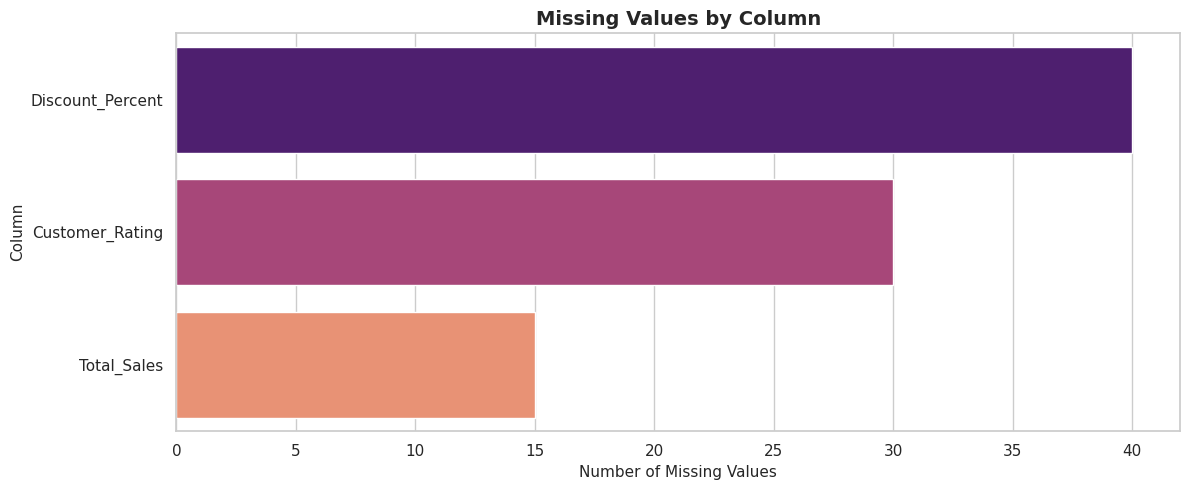

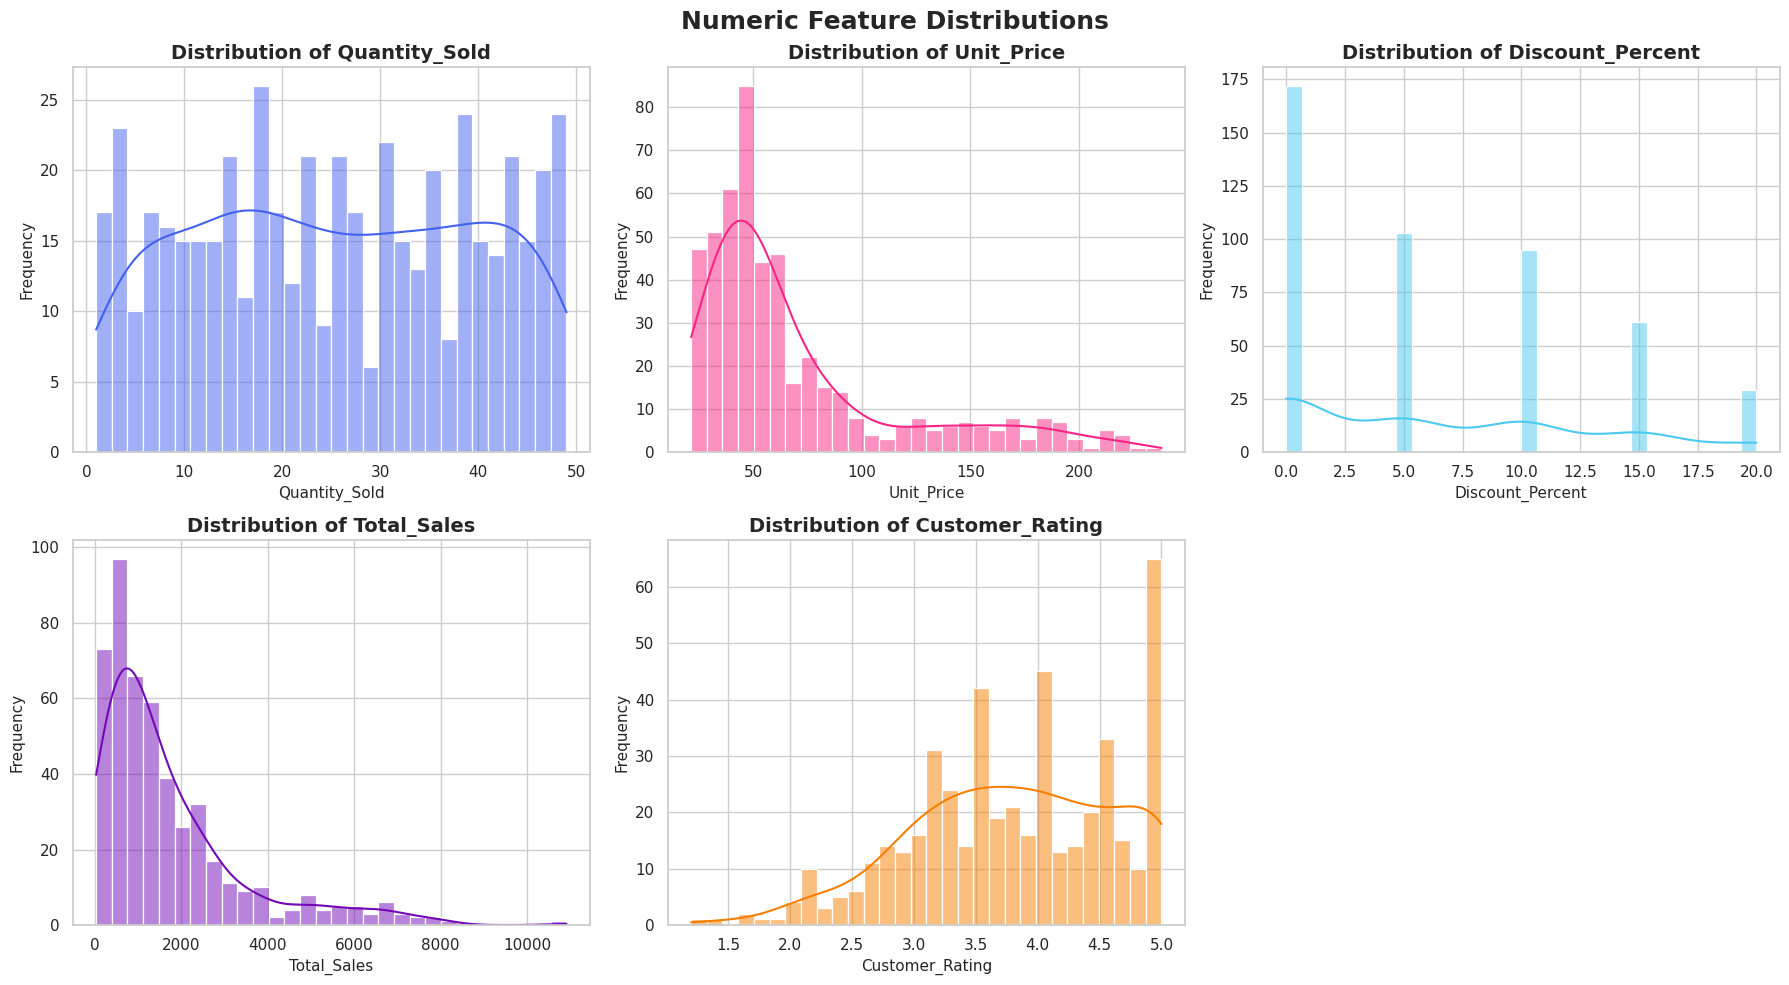

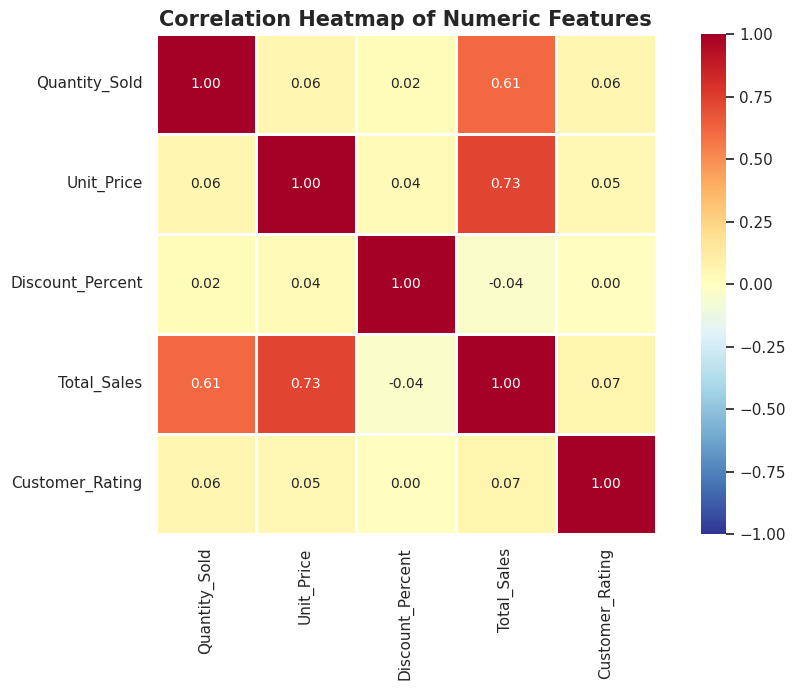

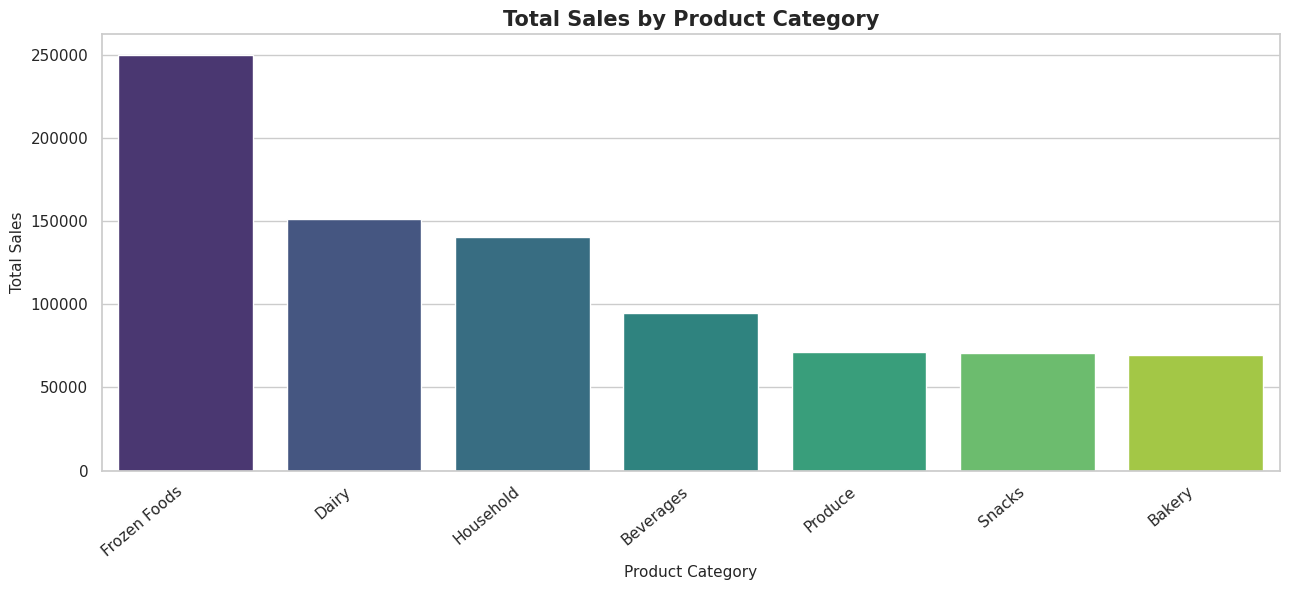

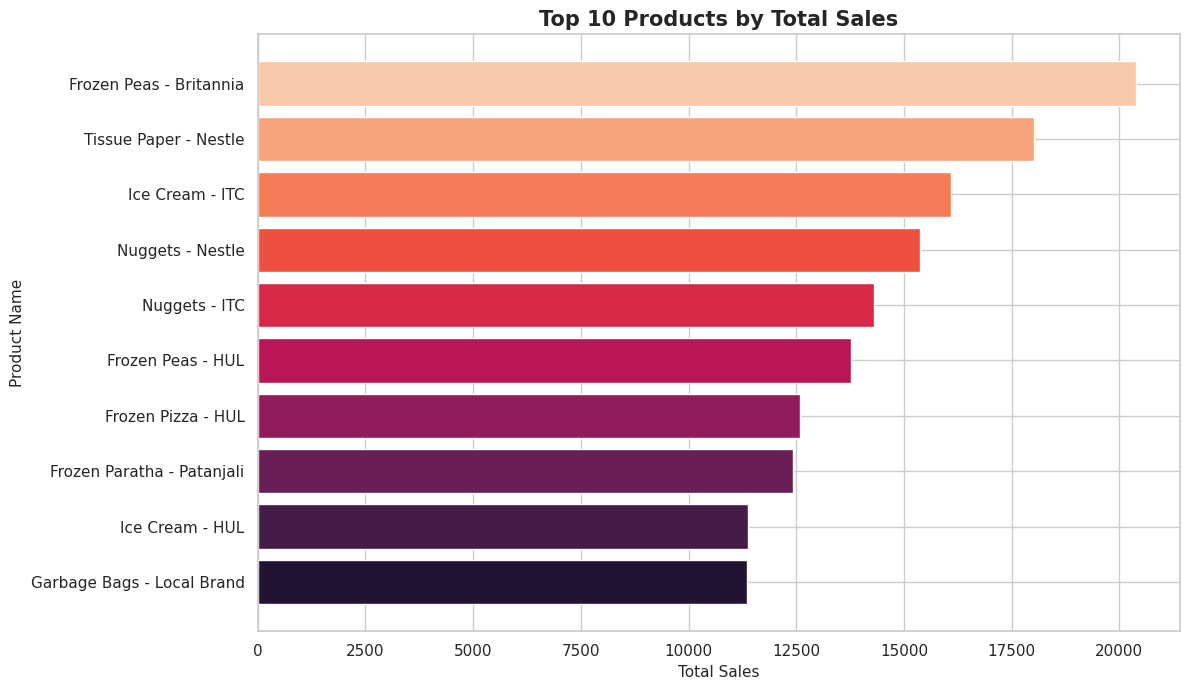

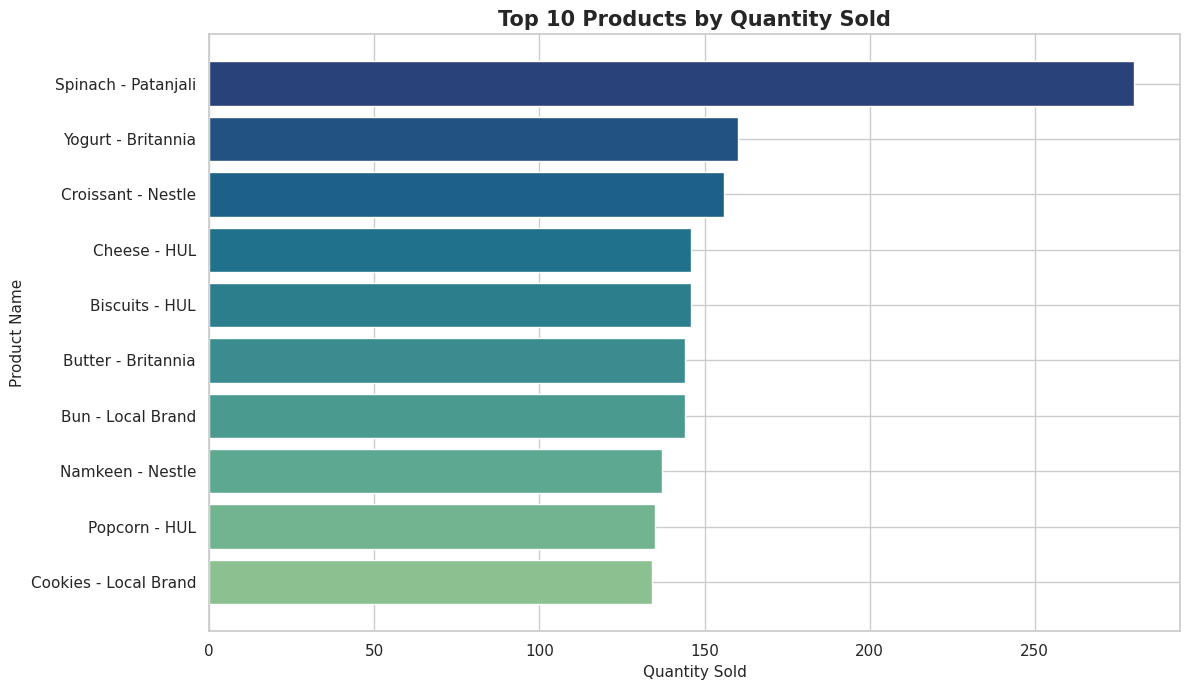

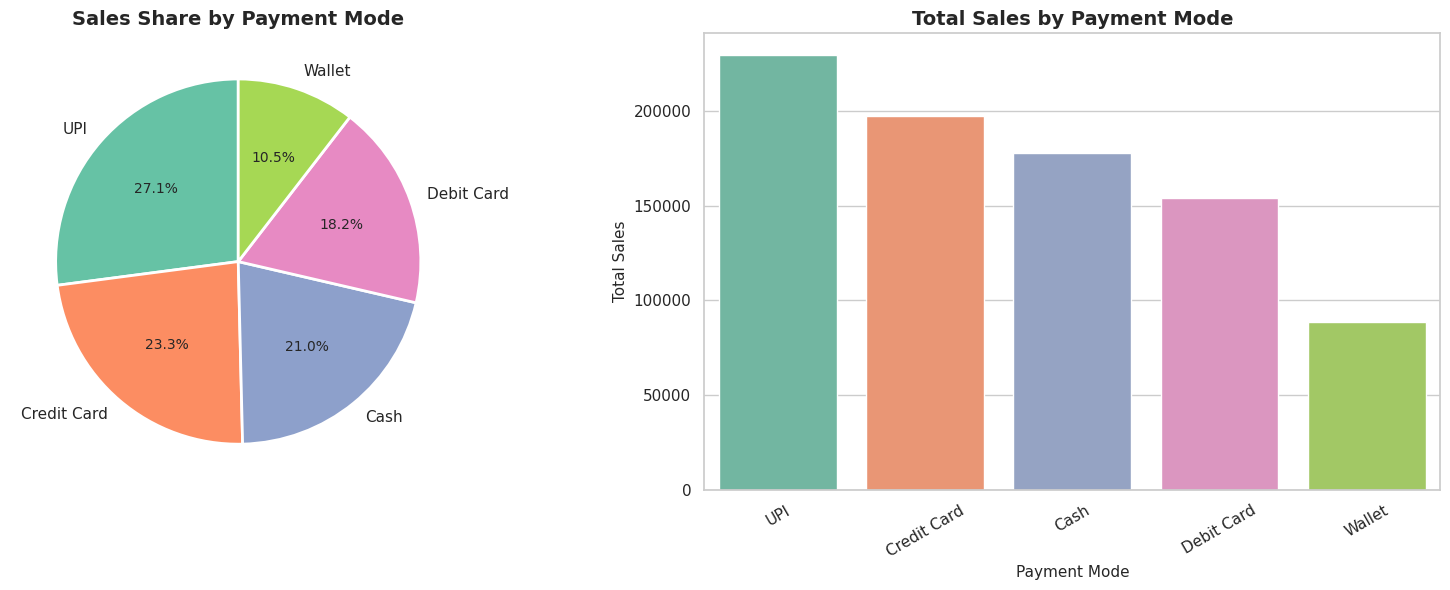

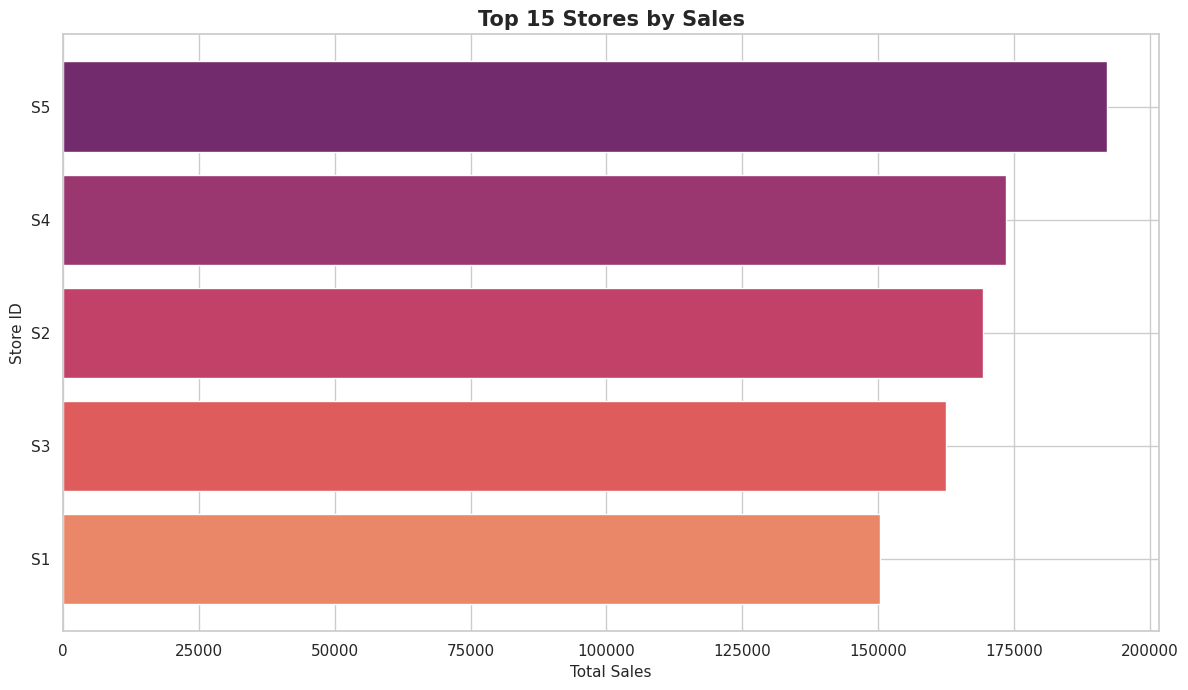

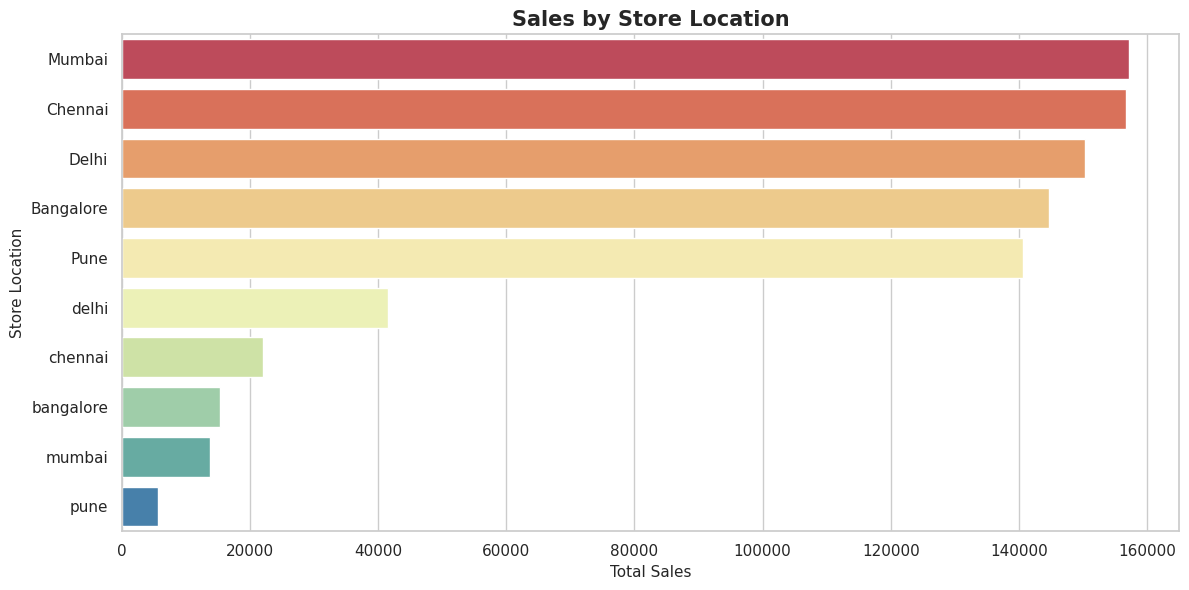

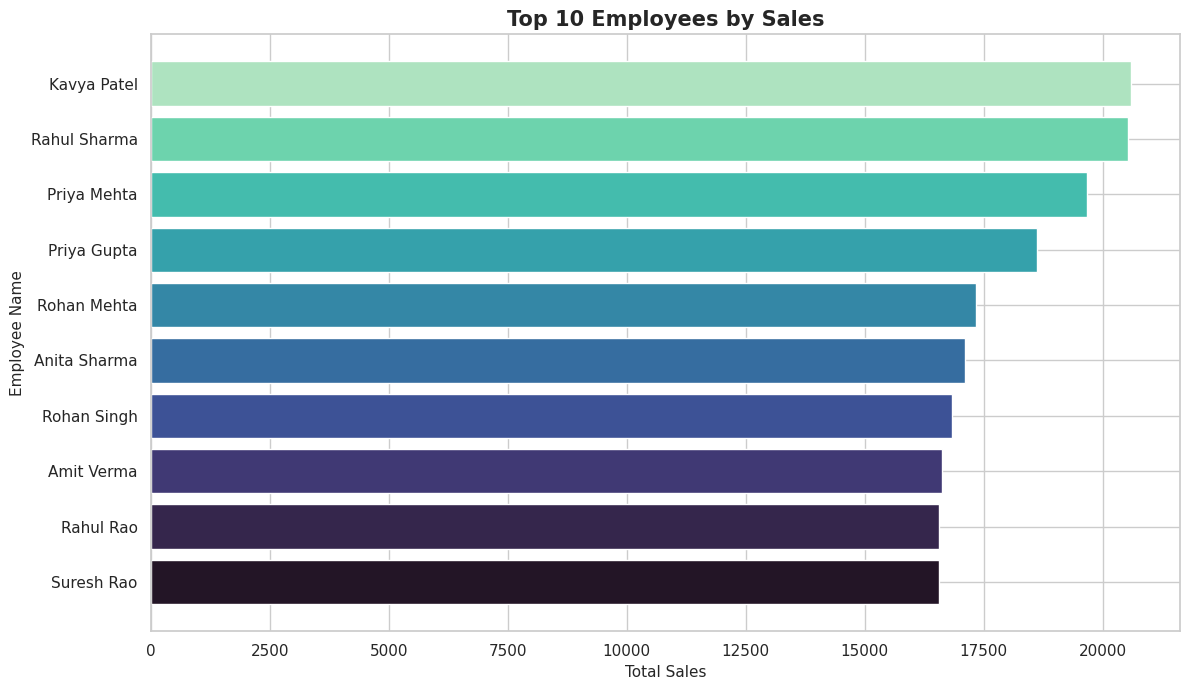

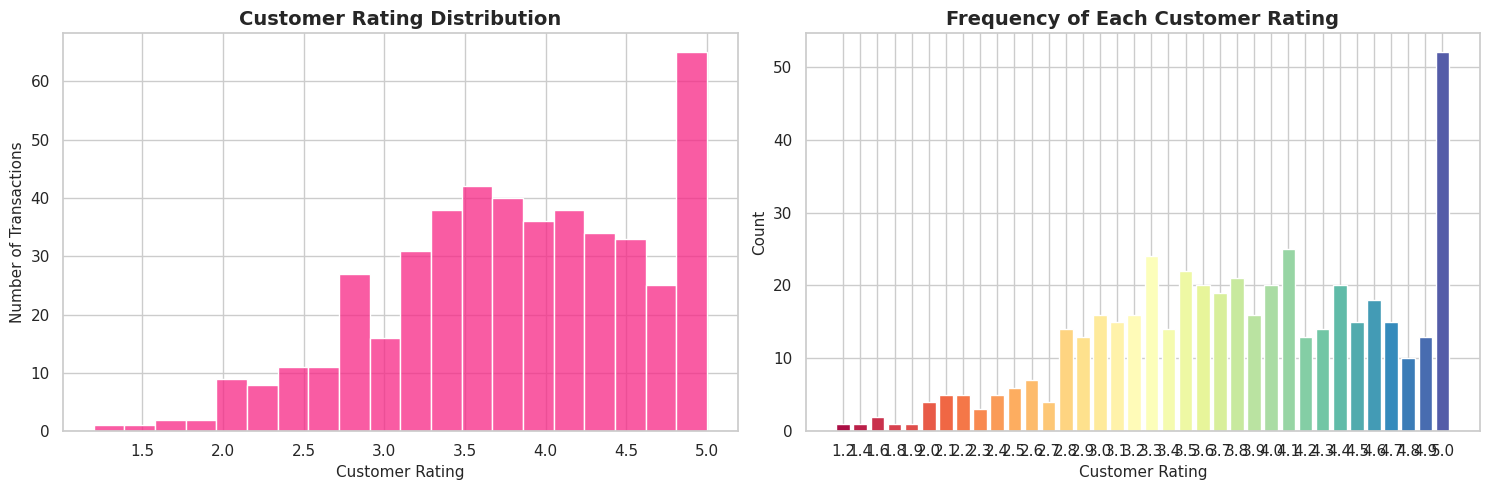

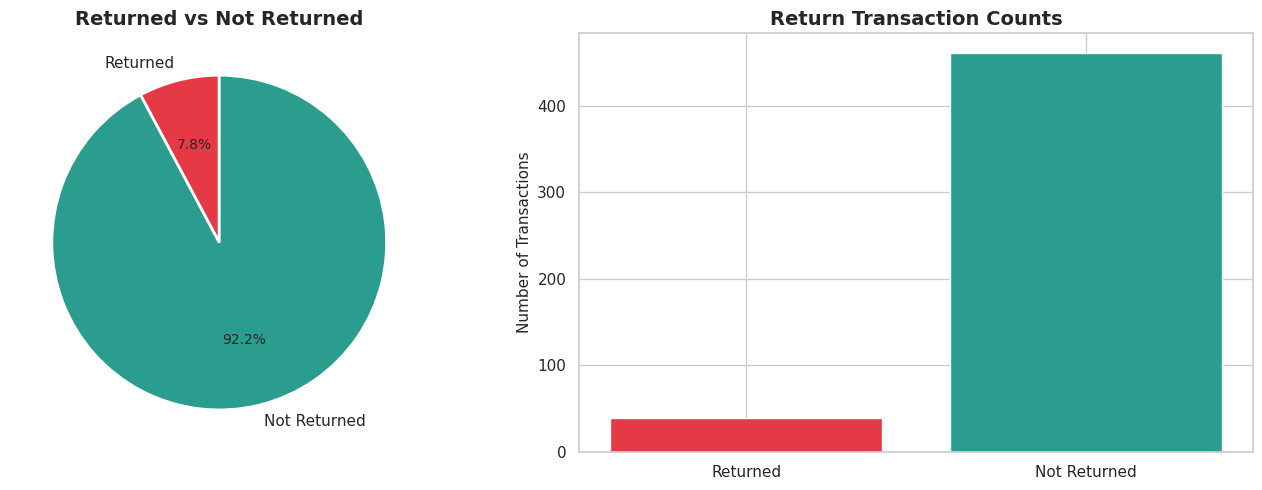

Return rate: 7.80%
Transactions with known return status: 500


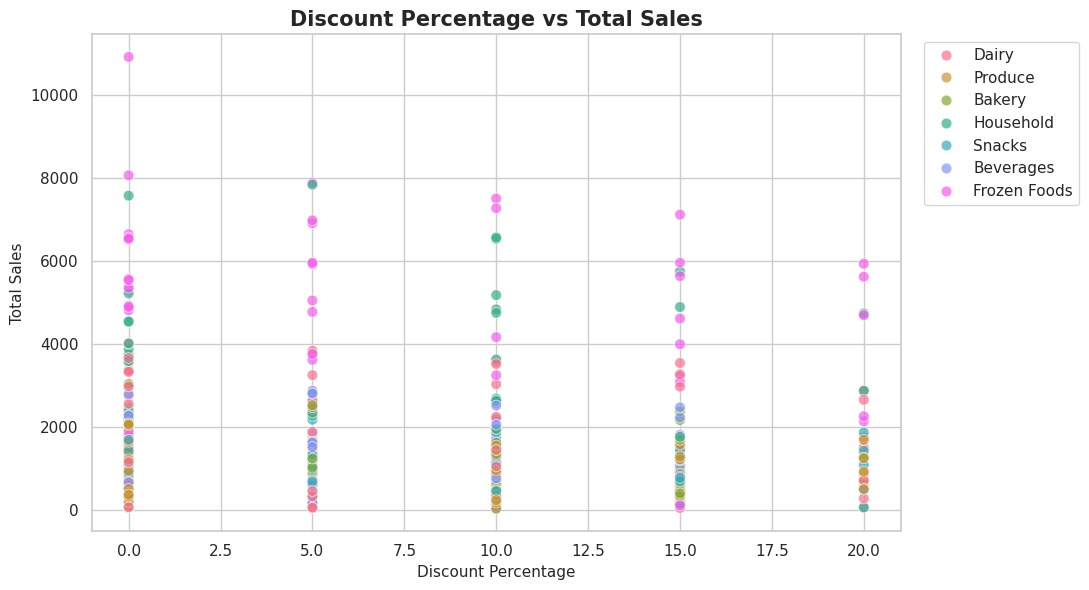

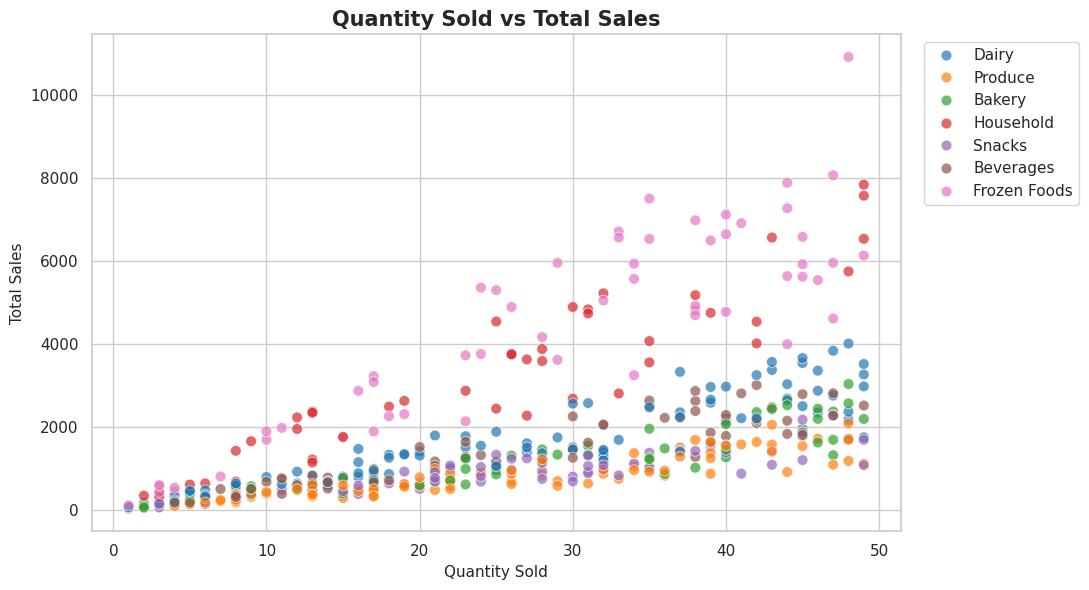

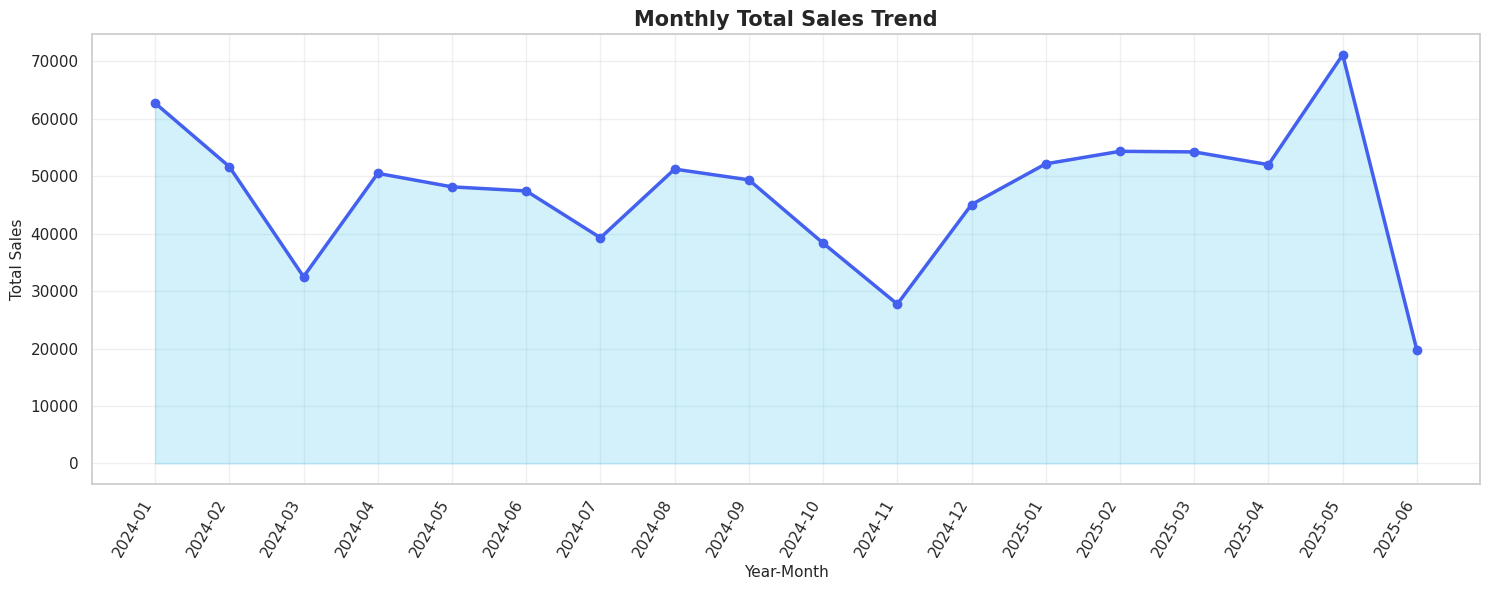

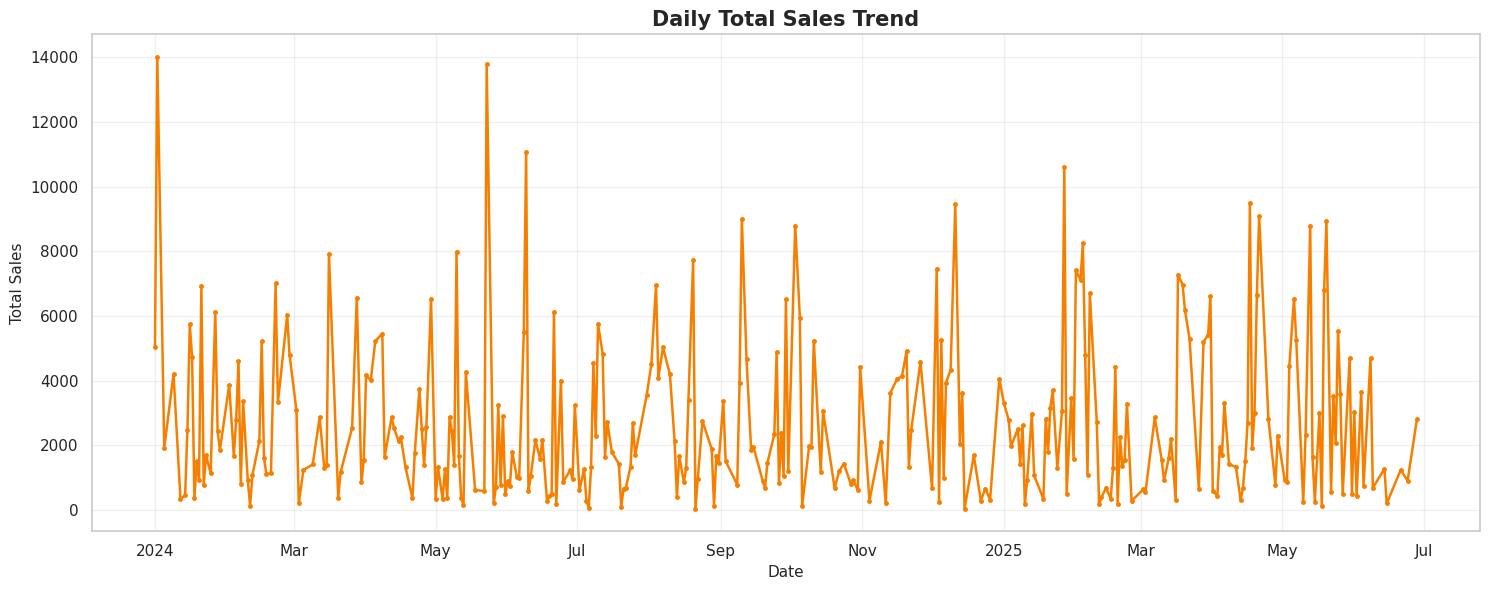

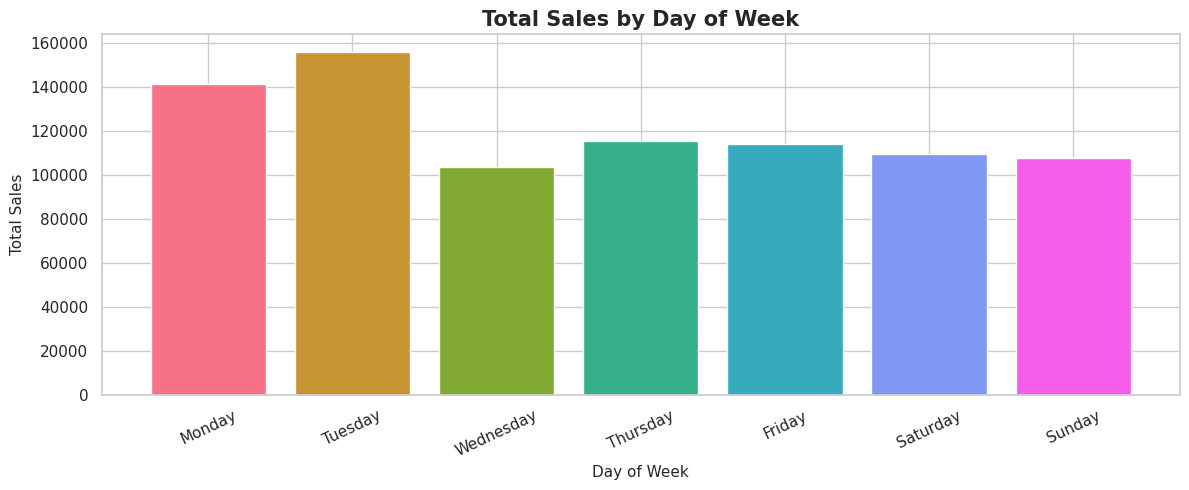

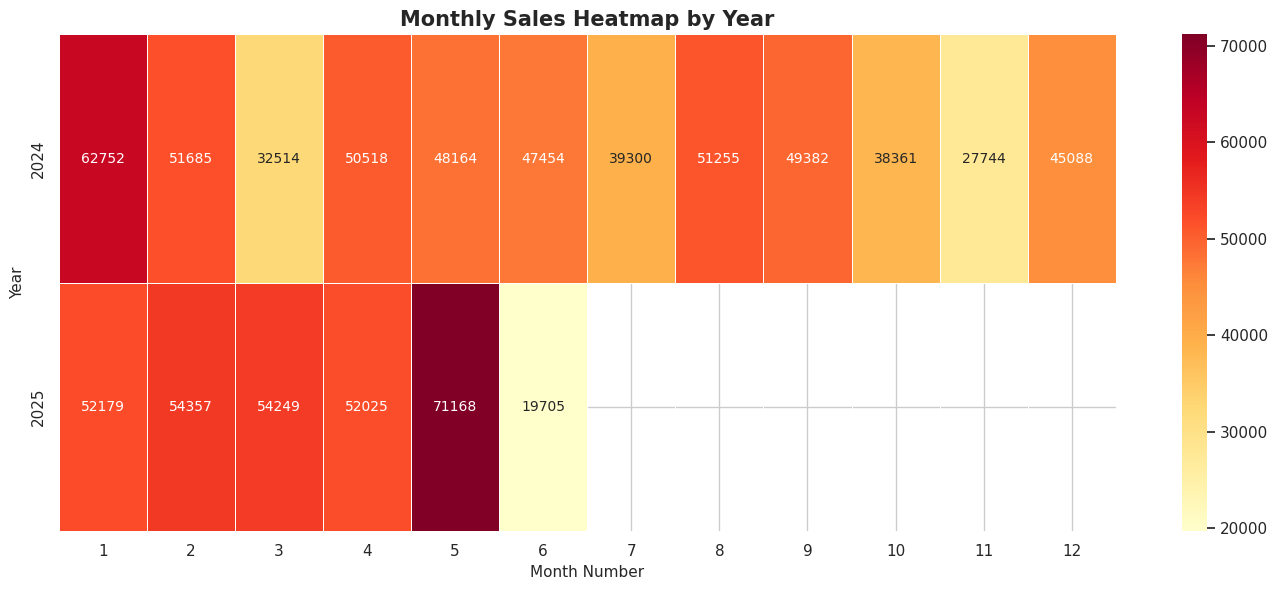

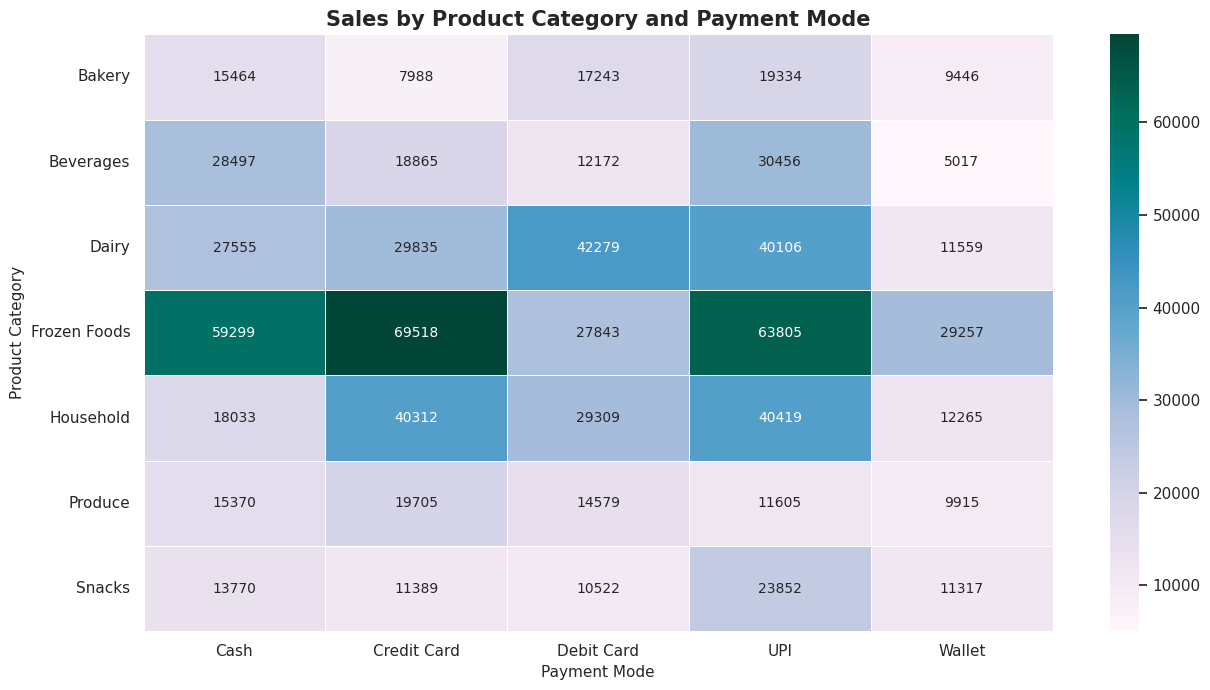

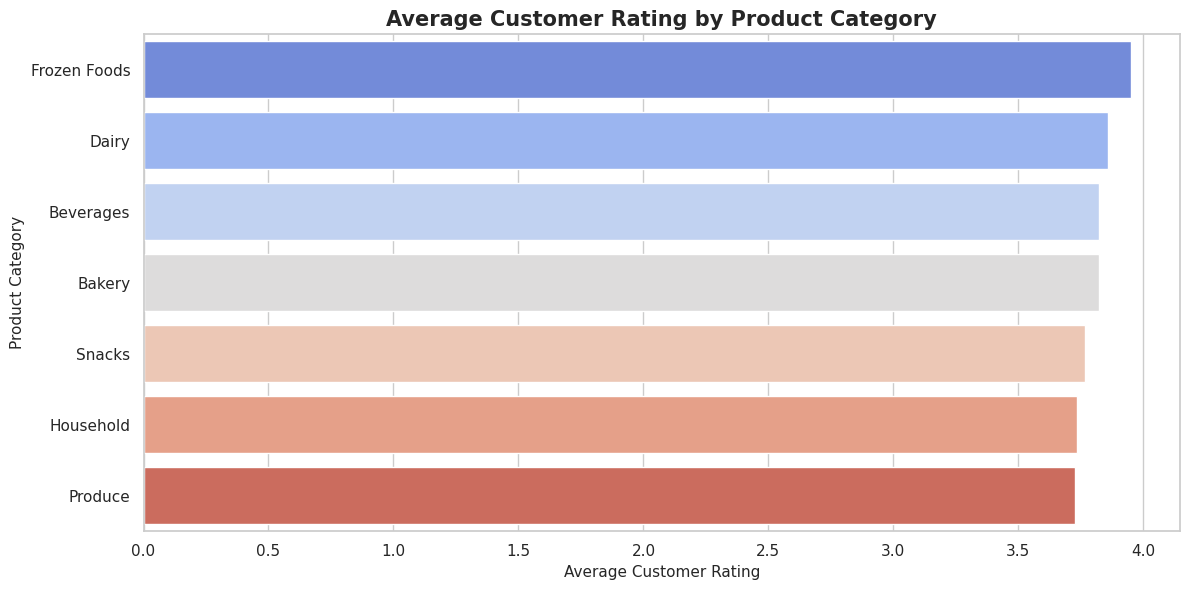

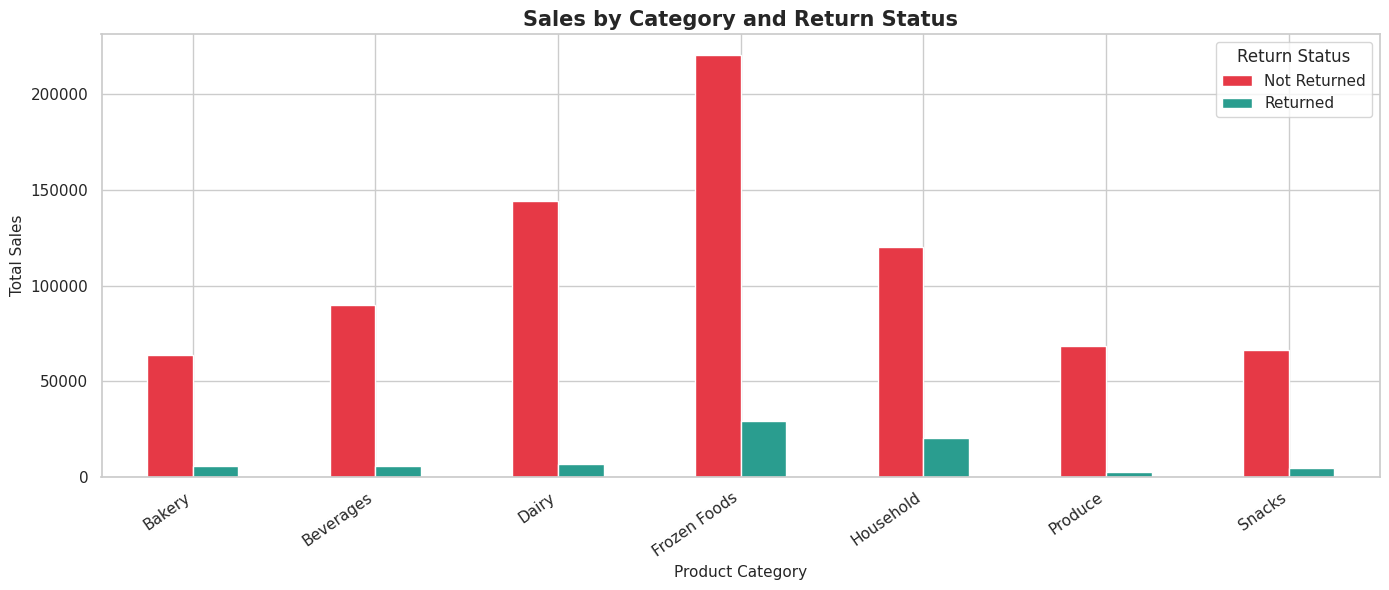

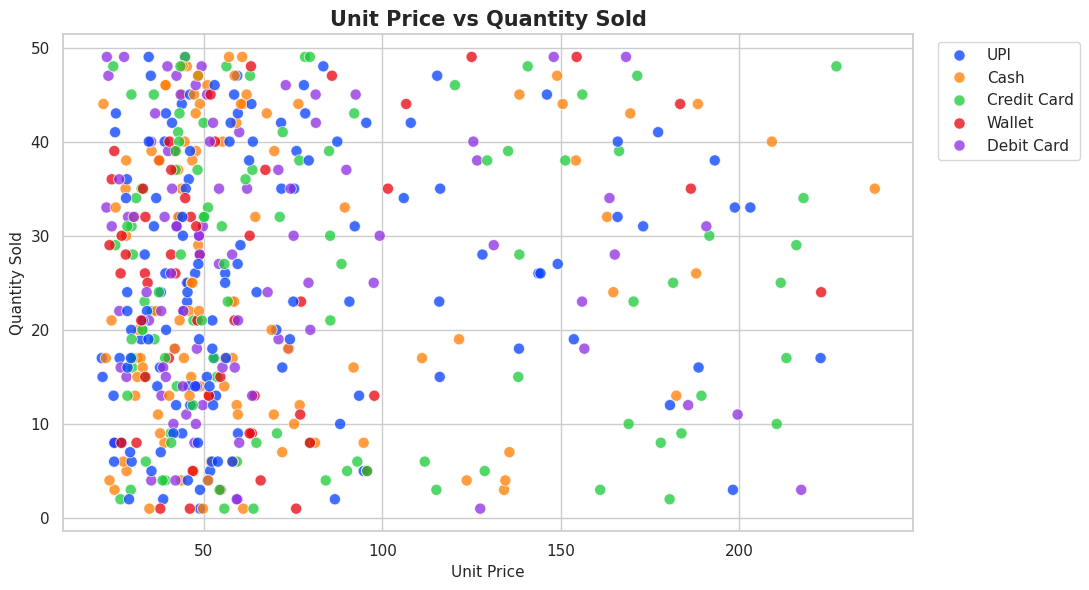

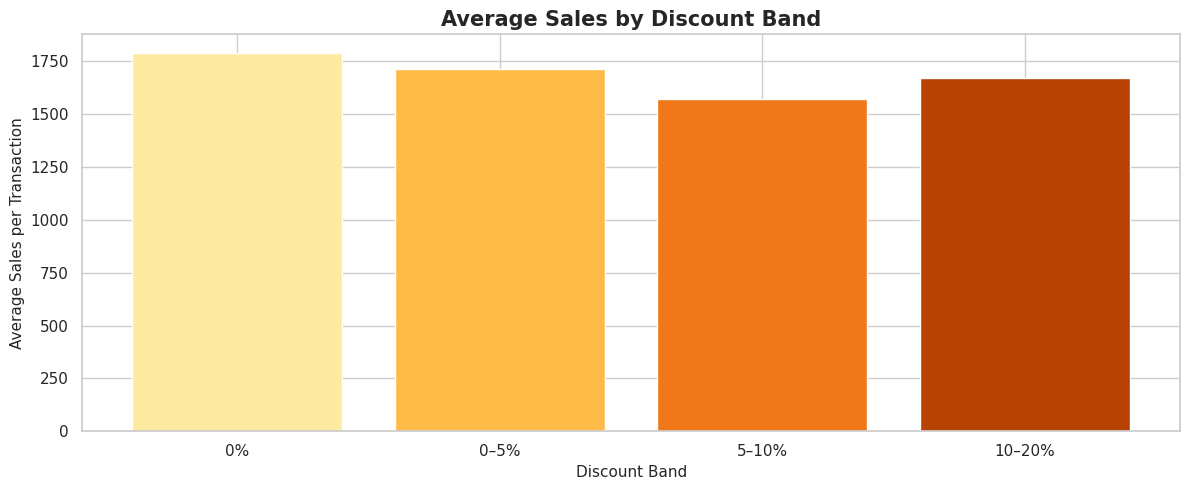

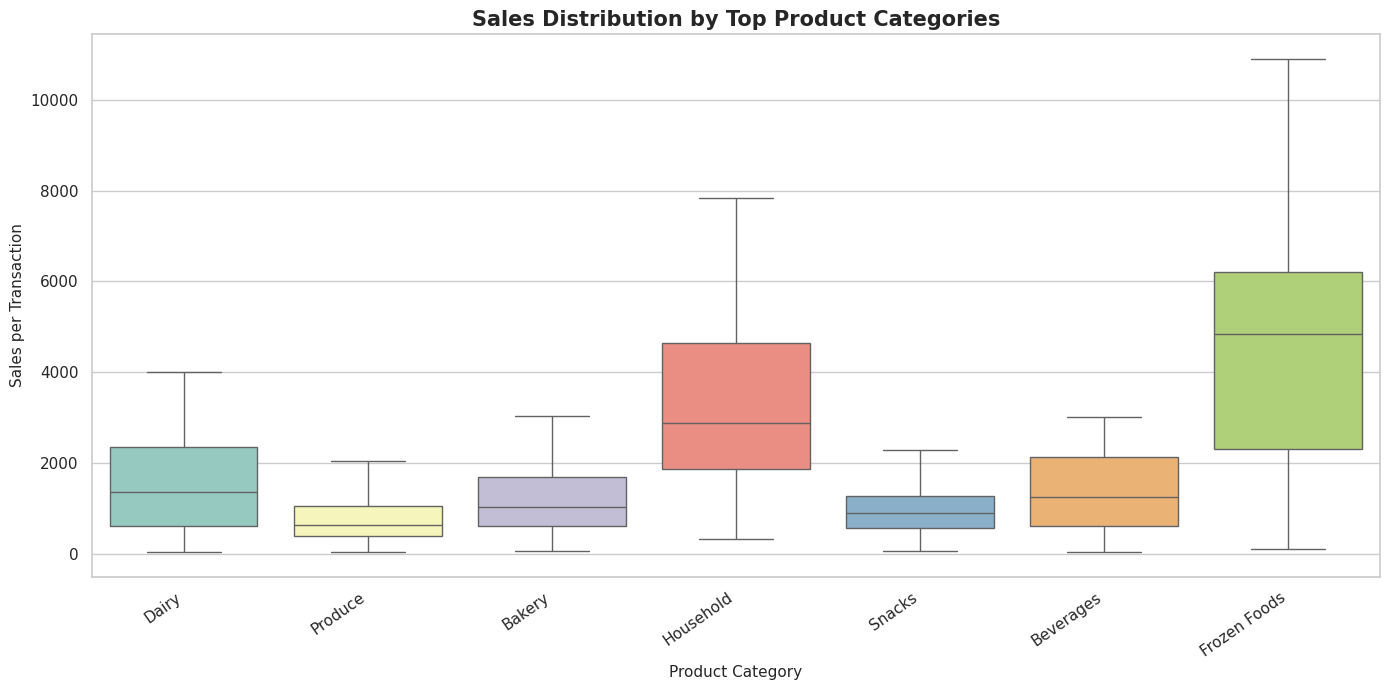

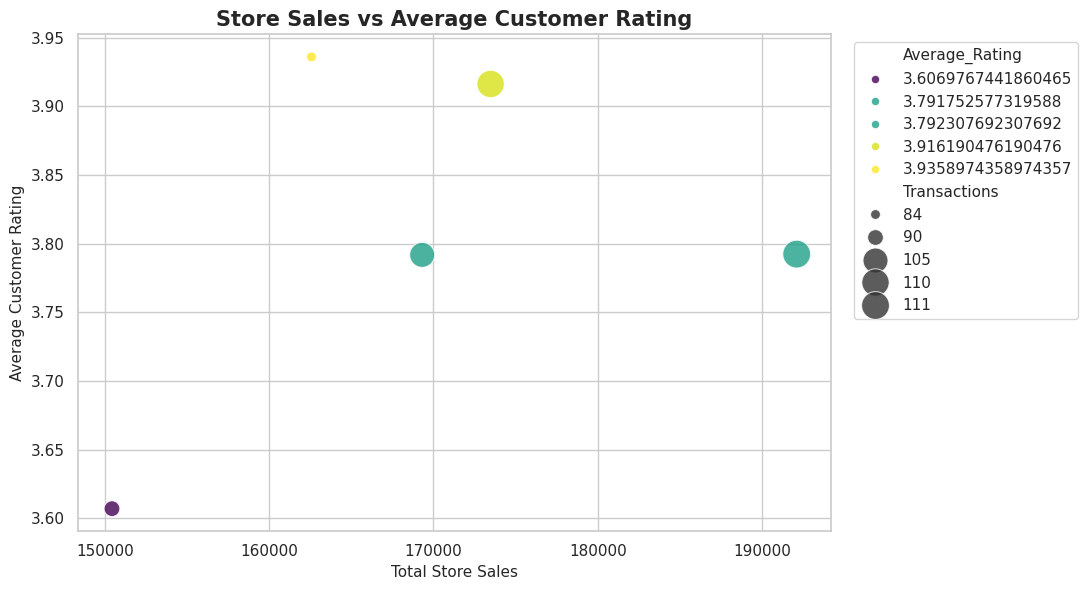

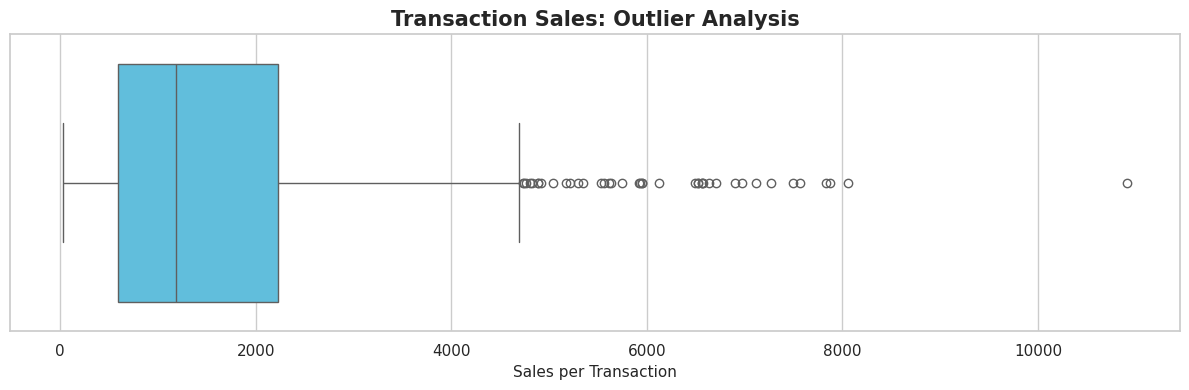

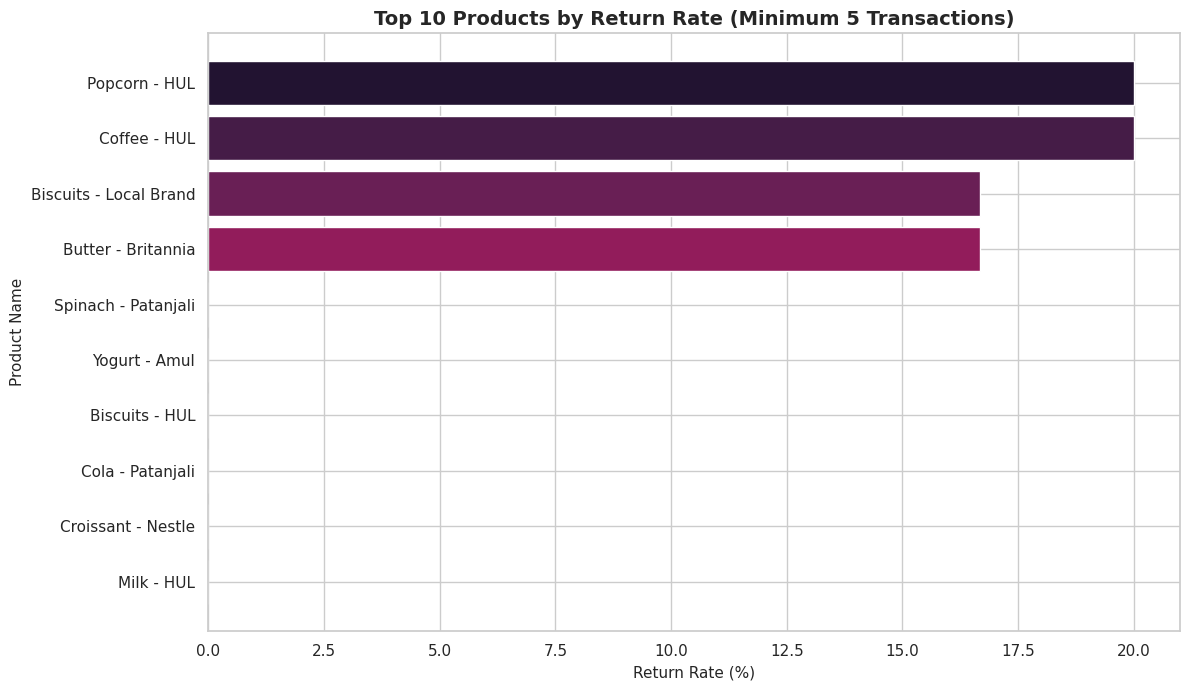


PRODUCT CATEGORY SUMMARY


,Total_Sales,Total_Quantity,Average_Unit_Price,Average_Discount,Average_Rating,Transactions
Product_Category,,,,,,
Frozen Foods,249722.20,1623.0,166.04,7.31,3.95,56
Dairy,151333.38,2416.0,66.36,5.79,3.86,100
Household,140339.33,1063.0,142.07,6.15,3.73,43
Beverages,95007.43,1746.0,56.65,6.03,3.82,71
Produce,71173.28,2198.0,34.43,6.18,3.73,93
Snacks,70850.26,2032.0,39.24,6.34,3.77,80
Bakery,69474.82,1587.0,46.34,7.91,3.82,57



PAYMENT MODE SUMMARY


,Transactions,Total_Sales,Average_Sales
Payment_Mode,,,
UPI,137,229576.40,1688.06
Credit Card,104,197611.47,1918.56
Cash,110,177988.55,1632.92
Debit Card,93,153948.20,1673.35
Wallet,56,88776.08,1585.29



STORE PERFORMANCE SUMMARY


Transactions  Total_Sales  Average_Rating  \
Store_ID Store_Location                                              
S5       Bangalore                 17     54649.92            3.83   
S1       Delhi                     23     52958.06            3.60   
S4       Chennai                   20     43548.16            4.24   
S5       Mumbai                    24     41762.42            3.78   
S4       Pune                      19     37639.33            3.95   
S1       Mumbai                    21     33919.70            3.74   
S2       Pune                      21     33001.94            3.77   
S5       Pune                      22     32842.90            3.78   
         Chennai                   21     32621.64            3.97   
S3       Delhi                     17     32181.07            3.74   
         Mumbai                    15     30724.34            4.01   
         Chennai                   14     30629.87            3.82   
S2       Bangalore                 17     29652.06            4.01   
         Mumbai                    22     27616.97            3.69   
         Chennai                   13     27103.93            3.94   
S3       Bangalore                 20     27038.94            4.16   
S2       Delhi                     16     26058.20            3.80   
S4       Bangalore                 21     23319.36            4.10   
         Mumbai                    18     23151.22            3.53   
S1       Chennai                   16     22777.92            3.53   

                         Total_Quantity  
Store_ID Store_Location                  
S5       Bangalore                563.0  
S1       Delhi                    642.0  
S4       Chennai                  623.0  
S5       Mumbai                   626.0  
S4       Pune                     475.0  
S1       Mumbai                   546.0  
S2       Pune                     617.0  
S5       Pune                     550.0  
         Chennai                  532.0  
S3       Delhi                    491.0  
         Mumbai                   382.0  
         Chennai                  432.0  
S2       Bangalore                358.0  
         Mumbai                   526.0  
         Chennai                  332.0  
S3       Bangalore                386.0  
S2       Delhi                    400.0  
S4       Bangalore                455.0  
         Mumbai                   399.0  
S1       Chennai                  383.0


VISUALIZATION COMPLETE
All available plots and summary tables have been generated.


In [13]:

import matplotlib.dates as mdates

from IPython.display import display

# ------------------------------------------------
# 1. DATA PREPARATION
# ------------------------------------------------

# Work on a copy so the original DataFrame remains unchanged
df = df.copy()

# Remove duplicate column names if any
df = df.loc[:, ~df.columns.duplicated()]

# Required columns
required_columns = [
    'Transaction_ID', 'Date', 'Store_ID', 'Store_Location',
    'Product_Category', 'Product_Name', 'Quantity_Sold',
    'Unit_Price', 'Discount_Percent', 'Total_Sales',
    'Payment_Mode', 'Customer_Rating', 'Employee_Name',
    'Contact', 'Returned'
]

missing_columns = [c for c in required_columns if c not in df.columns]

if missing_columns:
    raise ValueError(f"Missing columns in df: {missing_columns}")

# Convert numeric columns safely
numeric_columns = [
    'Quantity_Sold', 'Unit_Price', 'Discount_Percent',
    'Total_Sales', 'Customer_Rating'
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Convert Date to datetime
df['Date'] = pd.to_datetime(df['Date'], errors='coerce', dayfirst=True)

# Clean text columns for visualization
categorical_columns = [
    'Store_ID', 'Store_Location', 'Product_Category',
    'Product_Name', 'Payment_Mode', 'Employee_Name', 'Returned'
]

for col in categorical_columns:
    df[col] = df[col].astype('string').str.strip()
    df[col] = df[col].replace('', pd.NA)

# Remove invalid values from key numeric fields
df.loc[df['Quantity_Sold'] < 0, 'Quantity_Sold'] = np.nan
df.loc[df['Unit_Price'] < 0, 'Unit_Price'] = np.nan
df.loc[df['Discount_Percent'] < 0, 'Discount_Percent'] = np.nan

# Return values may be True/False, Yes/No, or 1/0
df['Returned_Flag'] = (
    df['Returned']
    .astype('string')
    .str.strip()
    .str.lower()
    .map({
        'true': 1, 'false': 0,
        'yes': 1, 'no': 0,
        'y': 1, 'n': 0,
        '1': 1, '0': 0,
        'returned': 1, 'not returned': 0
    })
)

# Create date-related columns
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Month_Name'] = df['Date'].dt.strftime('%b')
df['Year_Month'] = df['Date'].dt.to_period('M').astype('string')
df['Day_Name'] = df['Date'].dt.day_name()
df['Day_Number'] = df['Date'].dt.dayofweek

# Create helper columns for analysis
df['Calculated_Sales'] = (
    df['Quantity_Sold'] * df['Unit_Price']
    * (1 - df['Discount_Percent'].clip(0, 100) / 100)
)

# Use existing Total_Sales as the primary sales metric.
# Calculated_Sales is only an estimate if Total_Sales is unavailable.
df['Sales_For_Analysis'] = df['Total_Sales'].fillna(
    df['Calculated_Sales']
)

# Consistent visual theme
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['font.size'] = 10

# Custom color palette
colors = [
    '#4361EE', '#F72585', '#4CC9F0', '#7209B7',
    '#F77F00', '#2A9D8F', '#E63946', '#FFBE0B',
    '#8338EC', '#06D6A0', '#FB5607', '#3A86FF',
    '#B5179E', '#588157', '#BC6C25'
]

palette = sns.color_palette(colors)

print("=" * 70)
print("RETAIL TRANSACTION DATASET OVERVIEW")
print("=" * 70)

print(f"Number of transactions: {len(df):,}")
print(f"Number of columns: {df.shape[1]:,}")
print(f"Unique transaction IDs: {df['Transaction_ID'].nunique():,}")
print(f"Unique stores: {df['Store_ID'].nunique():,}")
print(f"Unique products: {df['Product_Name'].nunique():,}")
print(f"Total sales: {df['Sales_For_Analysis'].sum():,.2f}")
print(f"Average transaction sales: {df['Sales_For_Analysis'].mean():,.2f}")
print(f"Total quantity sold: {df['Quantity_Sold'].sum():,.0f}")
print(f"Average customer rating: {df['Customer_Rating'].mean():.2f}")
print(f"Missing values: {df.isna().sum().sum():,}")
print(f"Duplicate rows: {df.duplicated().sum():,}")

display(df[required_columns].head())

# ------------------------------------------------
# 2. MISSING VALUES VISUALIZATION
# ------------------------------------------------

missing = df[required_columns].isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if not missing.empty:
    plt.figure(figsize=(12, 5))
    sns.barplot(
        x=missing.values,
        y=missing.index,
        hue=missing.index,
        palette='magma',
        legend=False
    )
    plt.title('Missing Values by Column', fontweight='bold')
    plt.xlabel('Number of Missing Values')
    plt.ylabel('Column')
    plt.tight_layout()
    plt.show()
else:
    print("No missing values in the selected columns.")

# ------------------------------------------------
# 3. NUMERIC DATA DISTRIBUTIONS
# ------------------------------------------------

numeric_to_plot = [
    'Quantity_Sold', 'Unit_Price',
    'Discount_Percent', 'Total_Sales', 'Customer_Rating'
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(numeric_to_plot):
    values = df[col].dropna()

    if values.empty:
        axes[i].text(0.5, 0.5, 'No valid data',
                     ha='center', va='center')
        axes[i].set_title(col)
        continue

    sns.histplot(
        values, bins=30, kde=True,
        color=colors[i], ax=axes[i]
    )
    axes[i].set_title(f'Distribution of {col}', fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

axes[-1].axis('off')
plt.suptitle('Numeric Feature Distributions',
             fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 4. CORRELATION HEATMAP
# ------------------------------------------------

corr_cols = [
    'Quantity_Sold', 'Unit_Price',
    'Discount_Percent', 'Total_Sales', 'Customer_Rating'
]

corr = df[corr_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='RdYlBu_r',
    linewidths=0.8,
    square=True,
    vmin=-1,
    vmax=1
)
plt.title('Correlation Heatmap of Numeric Features',
          fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 5. PRODUCT CATEGORY SALES
# ------------------------------------------------

category_sales = (
    df.groupby('Product_Category', dropna=False)['Sales_For_Analysis']
    .sum()
    .sort_values(ascending=False)
    .dropna()
)

if not category_sales.empty:
    plt.figure(figsize=(13, 6))
    sns.barplot(
        x=category_sales.index.astype(str),
        y=category_sales.values,
        hue=category_sales.index.astype(str),
        palette='viridis',
        legend=False
    )
    plt.title('Total Sales by Product Category',
              fontsize=15, fontweight='bold')
    plt.xlabel('Product Category')
    plt.ylabel('Total Sales')
    plt.xticks(rotation=40, ha='right')
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 6. TOP 10 PRODUCTS BY SALES
# ------------------------------------------------

top_products = (
    df.groupby('Product_Name')['Sales_For_Analysis']
    .sum()
    .nlargest(10)
    .sort_values()
    .dropna()
)

if not top_products.empty:
    plt.figure(figsize=(12, 7))
    plt.barh(
        top_products.index.astype(str),
        top_products.values,
        color=sns.color_palette('rocket', len(top_products))
    )
    plt.title('Top 10 Products by Total Sales',
              fontsize=15, fontweight='bold')
    plt.xlabel('Total Sales')
    plt.ylabel('Product Name')
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 7. TOP 10 PRODUCTS BY QUANTITY SOLD
# ------------------------------------------------

top_quantity = (
    df.groupby('Product_Name')['Quantity_Sold']
    .sum()
    .nlargest(10)
    .sort_values()
    .dropna()
)

if not top_quantity.empty:
    plt.figure(figsize=(12, 7))
    plt.barh(
        top_quantity.index.astype(str),
        top_quantity.values,
        color=sns.color_palette('crest', len(top_quantity))
    )
    plt.title('Top 10 Products by Quantity Sold',
              fontsize=15, fontweight='bold')
    plt.xlabel('Quantity Sold')
    plt.ylabel('Product Name')
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 8. PAYMENT MODE ANALYSIS
# ------------------------------------------------

payment_sales = (
    df.groupby('Payment_Mode')['Sales_For_Analysis']
    .sum()
    .dropna()
    .sort_values(ascending=False)
)

if not payment_sales.empty:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    axes[0].pie(
        payment_sales.values,
        labels=payment_sales.index.astype(str),
        autopct='%1.1f%%',
        startangle=90,
        colors=sns.color_palette('Set2', len(payment_sales)),
        wedgeprops={'edgecolor': 'white', 'linewidth': 2}
    )
    axes[0].set_title('Sales Share by Payment Mode',
                      fontweight='bold')

    sns.barplot(
        x=payment_sales.index.astype(str),
        y=payment_sales.values,
        hue=payment_sales.index.astype(str),
        palette='Set2',
        legend=False,
        ax=axes[1]
    )
    axes[1].set_title('Total Sales by Payment Mode',
                      fontweight='bold')
    axes[1].set_xlabel('Payment Mode')
    axes[1].set_ylabel('Total Sales')
    axes[1].tick_params(axis='x', rotation=30)

    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 9. STORE PERFORMANCE
# ------------------------------------------------

store_sales = (
    df.groupby('Store_ID')['Sales_For_Analysis']
    .sum()
    .nlargest(15)
    .sort_values()
    .dropna()
)

if not store_sales.empty:
    plt.figure(figsize=(12, 7))
    plt.barh(
        store_sales.index.astype(str),
        store_sales.values,
        color=sns.color_palette('flare', len(store_sales))
    )
    plt.title('Top 15 Stores by Sales',
              fontsize=15, fontweight='bold')
    plt.xlabel('Total Sales')
    plt.ylabel('Store ID')
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 10. STORE LOCATION ANALYSIS
# ------------------------------------------------

location_sales = (
    df.groupby('Store_Location')['Sales_For_Analysis']
    .sum()
    .nlargest(15)
    .dropna()
    .sort_values(ascending=False)
)

if not location_sales.empty:
    plt.figure(figsize=(12, 6))
    sns.barplot(
        x=location_sales.values,
        y=location_sales.index.astype(str),
        hue=location_sales.index.astype(str),
        palette='Spectral',
        legend=False
    )
    plt.title('Sales by Store Location',
              fontsize=15, fontweight='bold')
    plt.xlabel('Total Sales')
    plt.ylabel('Store Location')
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 11. EMPLOYEE PERFORMANCE
# ------------------------------------------------

employee_sales = (
    df.groupby('Employee_Name')['Sales_For_Analysis']
    .sum()
    .nlargest(10)
    .sort_values()
    .dropna()
)

if not employee_sales.empty:
    plt.figure(figsize=(12, 7))
    plt.barh(
        employee_sales.index.astype(str),
        employee_sales.values,
        color=sns.color_palette('mako', len(employee_sales))
    )
    plt.title('Top 10 Employees by Sales',
              fontsize=15, fontweight='bold')
    plt.xlabel('Total Sales')
    plt.ylabel('Employee Name')
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 12. CUSTOMER RATINGS
# ------------------------------------------------

ratings = df['Customer_Rating'].dropna()

if not ratings.empty:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    sns.histplot(
        ratings,
        bins=min(20, max(1, ratings.nunique())),
        kde=False,
        color='#F72585',
        ax=axes[0]
    )
    axes[0].set_title('Customer Rating Distribution',
                      fontweight='bold')
    axes[0].set_xlabel('Customer Rating')
    axes[0].set_ylabel('Number of Transactions')

    rating_counts = ratings.value_counts().sort_index()

    axes[1].bar(
        rating_counts.index.astype(str),
        rating_counts.values,
        color=sns.color_palette('Spectral', len(rating_counts))
    )
    axes[1].set_title('Frequency of Each Customer Rating',
                      fontweight='bold')
    axes[1].set_xlabel('Customer Rating')
    axes[1].set_ylabel('Count')

    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 13. RETURNED VS NOT RETURNED
# ------------------------------------------------

return_data = df['Returned_Flag'].dropna()

if not return_data.empty:
    return_labels = return_data.map({
        1: 'Returned',
        0: 'Not Returned'
    })

    return_counts = return_labels.value_counts().reindex(
        ['Returned', 'Not Returned'], fill_value=0
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].pie(
        return_counts.values,
        labels=return_counts.index,
        autopct='%1.1f%%',
        startangle=90,
        colors=['#E63946', '#2A9D8F'],
        wedgeprops={'edgecolor': 'white', 'linewidth': 2}
    )
    axes[0].set_title('Returned vs Not Returned',
                      fontweight='bold')

    axes[1].bar(
        return_counts.index,
        return_counts.values,
        color=['#E63946', '#2A9D8F']
    )
    axes[1].set_title('Return Transaction Counts',
                      fontweight='bold')
    axes[1].set_ylabel('Number of Transactions')

    plt.tight_layout()
    plt.show()

    print(f"Return rate: {return_data.mean() * 100:.2f}%")
    print(f"Transactions with known return status: {len(return_data):,}")
else:
    print("Return analysis unavailable: Returned values could not be mapped.")

# ------------------------------------------------
# 14. DISCOUNT ANALYSIS
# ------------------------------------------------

discount_data = df.dropna(
    subset=['Discount_Percent', 'Sales_For_Analysis']
)

if not discount_data.empty:
    plt.figure(figsize=(11, 6))
    sns.scatterplot(
        data=discount_data,
        x='Discount_Percent',
        y='Sales_For_Analysis',
        hue='Product_Category',
        palette='husl',
        alpha=0.7,
        s=60
    )
    plt.title('Discount Percentage vs Total Sales',
              fontsize=15, fontweight='bold')
    plt.xlabel('Discount Percentage')
    plt.ylabel('Total Sales')
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 15. QUANTITY SOLD VS TOTAL SALES
# ------------------------------------------------

quantity_sales = df.dropna(
    subset=['Quantity_Sold', 'Sales_For_Analysis']
)

if not quantity_sales.empty:
    plt.figure(figsize=(11, 6))
    sns.scatterplot(
        data=quantity_sales,
        x='Quantity_Sold',
        y='Sales_For_Analysis',
        hue='Product_Category',
        palette='tab10',
        alpha=0.7,
        s=60
    )
    plt.title('Quantity Sold vs Total Sales',
              fontsize=15, fontweight='bold')
    plt.xlabel('Quantity Sold')
    plt.ylabel('Total Sales')
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 16. MONTHLY SALES TREND
# ------------------------------------------------

monthly_data = df.dropna(
    subset=['Date', 'Sales_For_Analysis']
)

if not monthly_data.empty:
    monthly_sales = (
        monthly_data.groupby('Year_Month')['Sales_For_Analysis']
        .sum()
        .sort_index()
    )

    plt.figure(figsize=(15, 6))
    plt.plot(
        monthly_sales.index.astype(str),
        monthly_sales.values,
        color='#4361EE',
        marker='o',
        linewidth=2.5,
        markersize=6
    )
    plt.fill_between(
        range(len(monthly_sales)),
        monthly_sales.values,
        color='#4CC9F0',
        alpha=0.25
    )
    plt.title('Monthly Total Sales Trend',
              fontsize=15, fontweight='bold')
    plt.xlabel('Year-Month')
    plt.ylabel('Total Sales')
    plt.xticks(rotation=60, ha='right')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 17. DAILY SALES TREND
# ------------------------------------------------

if not monthly_data.empty:
    daily_sales = (
        monthly_data.groupby('Date')['Sales_For_Analysis']
        .sum()
        .sort_index()
    )

    plt.figure(figsize=(15, 6))
    plt.plot(
        daily_sales.index,
        daily_sales.values,
        color='#F77F00',
        linewidth=1.8,
        marker='.',
        markersize=5
    )
    plt.title('Daily Total Sales Trend',
              fontsize=15, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Total Sales')
    plt.gca().xaxis.set_major_locator(mdates.AutoDateLocator())
    plt.gca().xaxis.set_major_formatter(
        mdates.ConciseDateFormatter(
            mdates.AutoDateLocator()
        )
    )
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 18. SALES BY DAY OF WEEK
# ------------------------------------------------

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_sales = (
    monthly_data.groupby('Day_Name')['Sales_For_Analysis']
    .sum()
    .reindex(weekday_order)
    .dropna()
)

if not weekday_sales.empty:
    plt.figure(figsize=(12, 5))
    plt.bar(
        weekday_sales.index,
        weekday_sales.values,
        color=sns.color_palette('husl', len(weekday_sales))
    )
    plt.title('Total Sales by Day of Week',
              fontsize=15, fontweight='bold')
    plt.xlabel('Day of Week')
    plt.ylabel('Total Sales')
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 19. MONTHLY SALES HEATMAP
# ------------------------------------------------

if not monthly_data.empty:
    heatmap_data = monthly_data.copy()
    heatmap_data['Year'] = heatmap_data['Date'].dt.year
    heatmap_data['Month'] = heatmap_data['Date'].dt.month

    monthly_pivot = heatmap_data.pivot_table(
        index='Year',
        columns='Month',
        values='Sales_For_Analysis',
        aggfunc='sum'
    )

    if not monthly_pivot.empty:
        plt.figure(figsize=(14, 6))
        sns.heatmap(
            monthly_pivot,
            annot=True,
            fmt='.0f',
            cmap='YlOrRd',
            linewidths=0.5
        )
        plt.title('Monthly Sales Heatmap by Year',
                  fontsize=15, fontweight='bold')
        plt.xlabel('Month Number')
        plt.ylabel('Year')
        plt.tight_layout()
        plt.show()

# ------------------------------------------------
# 20. PRODUCT CATEGORY VS PAYMENT MODE
# ------------------------------------------------

category_payment = df.pivot_table(
    index='Product_Category',
    columns='Payment_Mode',
    values='Sales_For_Analysis',
    aggfunc='sum',
    fill_value=0
)

if not category_payment.empty:
    plt.figure(figsize=(13, 7))
    sns.heatmap(
        category_payment,
        annot=True,
        fmt='.0f',
        cmap='PuBuGn',
        linewidths=0.5
    )
    plt.title('Sales by Product Category and Payment Mode',
              fontsize=15, fontweight='bold')
    plt.xlabel('Payment Mode')
    plt.ylabel('Product Category')
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 21. CUSTOMER RATING BY PRODUCT CATEGORY
# ------------------------------------------------

rating_category = (
    df.groupby('Product_Category')['Customer_Rating']
    .mean()
    .dropna()
    .sort_values(ascending=False)
)

if not rating_category.empty:
    plt.figure(figsize=(12, 6))
    sns.barplot(
        x=rating_category.values,
        y=rating_category.index.astype(str),
        hue=rating_category.index.astype(str),
        palette='coolwarm',
        legend=False
    )
    plt.title('Average Customer Rating by Product Category',
              fontsize=15, fontweight='bold')
    plt.xlabel('Average Customer Rating')
    plt.ylabel('Product Category')
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 22. SALES BY RETURN STATUS AND CATEGORY
# ------------------------------------------------

return_category = df.dropna(
    subset=['Returned_Flag', 'Product_Category', 'Sales_For_Analysis']
).copy()

if not return_category.empty:
    return_category['Return_Status'] = return_category[
        'Returned_Flag'
    ].map({1: 'Returned', 0: 'Not Returned'})

    return_category_summary = return_category.pivot_table(
        index='Product_Category',
        columns='Return_Status',
        values='Sales_For_Analysis',
        aggfunc='sum',
        fill_value=0
    )

    if not return_category_summary.empty:
        return_category_summary.plot(
            kind='bar',
            figsize=(14, 6),
            color=['#E63946', '#2A9D8F']
        )
        plt.title('Sales by Category and Return Status',
                  fontsize=15, fontweight='bold')
        plt.xlabel('Product Category')
        plt.ylabel('Total Sales')
        plt.xticks(rotation=35, ha='right')
        plt.legend(title='Return Status')
        plt.tight_layout()
        plt.show()

# ------------------------------------------------
# 23. UNIT PRICE VS QUANTITY SOLD
# ------------------------------------------------

price_quantity = df.dropna(
    subset=['Unit_Price', 'Quantity_Sold']
)

if not price_quantity.empty:
    plt.figure(figsize=(11, 6))
    sns.scatterplot(
        data=price_quantity,
        x='Unit_Price',
        y='Quantity_Sold',
        hue='Payment_Mode',
        palette='bright',
        alpha=0.75,
        s=65
    )
    plt.title('Unit Price vs Quantity Sold',
              fontsize=15, fontweight='bold')
    plt.xlabel('Unit Price')
    plt.ylabel('Quantity Sold')
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 24. DISCOUNT LEVEL VS AVERAGE SALES
# ------------------------------------------------

discount_df = df.dropna(
    subset=['Discount_Percent', 'Sales_For_Analysis']
).copy()

if not discount_df.empty:
    discount_df['Discount_Band'] = pd.cut(
        discount_df['Discount_Percent'],
        bins=[-0.01, 0, 5, 10, 20, 30, 50, 100],
        labels=[
            '0%', '0–5%', '5–10%', '10–20%',
            '20–30%', '30–50%', '50–100%'
        ],
        include_lowest=True
    )

    discount_summary = (
        discount_df.groupby('Discount_Band', observed=False)
        ['Sales_For_Analysis']
        .mean()
        .dropna()
    )

    if not discount_summary.empty:
        plt.figure(figsize=(12, 5))
        plt.bar(
            discount_summary.index.astype(str),
            discount_summary.values,
            color=sns.color_palette(
                'YlOrBr', len(discount_summary)
            )
        )
        plt.title('Average Sales by Discount Band',
                  fontsize=15, fontweight='bold')
        plt.xlabel('Discount Band')
        plt.ylabel('Average Sales per Transaction')
        plt.tight_layout()
        plt.show()

# ------------------------------------------------
# 25. SALES BOXPLOT BY PRODUCT CATEGORY
# ------------------------------------------------

box_df = df.dropna(
    subset=['Product_Category', 'Sales_For_Analysis']
).copy()

if not box_df.empty:
    top_categories = (
        box_df.groupby('Product_Category')['Sales_For_Analysis']
        .sum()
        .nlargest(10)
        .index
    )

    box_df = box_df[
        box_df['Product_Category'].isin(top_categories)
    ]

    if not box_df.empty:
        plt.figure(figsize=(14, 7))
        sns.boxplot(
            data=box_df,
            x='Product_Category',
            y='Sales_For_Analysis',
            hue='Product_Category',
            palette='Set3',
            legend=False,
            showfliers=False
        )
        plt.title('Sales Distribution by Top Product Categories',
                  fontsize=15, fontweight='bold')
        plt.xlabel('Product Category')
        plt.ylabel('Sales per Transaction')
        plt.xticks(rotation=35, ha='right')
        plt.tight_layout()
        plt.show()

# ------------------------------------------------
# 26. STORE SALES VS AVERAGE CUSTOMER RATING
# ------------------------------------------------

store_metrics = (
    df.groupby('Store_ID')
    .agg(
        Total_Sales=('Sales_For_Analysis', 'sum'),
        Average_Rating=('Customer_Rating', 'mean'),
        Transactions=('Transaction_ID', 'count')
    )
    .dropna(subset=['Total_Sales', 'Average_Rating'])
)

if not store_metrics.empty:
    plt.figure(figsize=(11, 6))
    sns.scatterplot(
        data=store_metrics,
        x='Total_Sales',
        y='Average_Rating',
        size='Transactions',
        hue='Average_Rating',
        palette='viridis',
        sizes=(50, 400),
        alpha=0.8
    )
    plt.title('Store Sales vs Average Customer Rating',
              fontsize=15, fontweight='bold')
    plt.xlabel('Total Store Sales')
    plt.ylabel('Average Customer Rating')
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 27. TRANSACTION SALES BOXPLOT
# ------------------------------------------------

sales_values = df['Sales_For_Analysis'].dropna()

if not sales_values.empty:
    plt.figure(figsize=(12, 4))
    sns.boxplot(
        x=sales_values,
        color='#4CC9F0',
        showfliers=True
    )
    plt.title('Transaction Sales: Outlier Analysis',
              fontsize=15, fontweight='bold')
    plt.xlabel('Sales per Transaction')
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 28. TOP PRODUCTS WITH RETURNS
# ------------------------------------------------

return_product = df.dropna(
    subset=['Returned_Flag', 'Product_Name']
).copy()

if not return_product.empty:
    product_return = (
        return_product.groupby('Product_Name')
        .agg(
            Transactions=('Transaction_ID', 'count'),
            Returns=('Returned_Flag', 'sum')
        )
    )

    # Restrict to products with sufficient transactions
    product_return = product_return[
        product_return['Transactions'] >= 5
    ]

    product_return['Return_Rate_Percent'] = (
        100 * product_return['Returns']
        / product_return['Transactions']
    )

    product_return = product_return[
        product_return['Transactions'] > 0
    ].nlargest(10, 'Return_Rate_Percent').sort_values(
        'Return_Rate_Percent'
    )

    if not product_return.empty:
        plt.figure(figsize=(12, 7))
        plt.barh(
            product_return.index.astype(str),
            product_return['Return_Rate_Percent'],
            color=sns.color_palette(
                'rocket_r', len(product_return)
            )
        )
        plt.title('Top 10 Products by Return Rate (Minimum 5 Transactions)',
                  fontsize=14, fontweight='bold')
        plt.xlabel('Return Rate (%)')
        plt.ylabel('Product Name')
        plt.tight_layout()
        plt.show()

# ------------------------------------------------
# 29. SUMMARY TABLES
# ------------------------------------------------

print("\n" + "=" * 70)
print("PRODUCT CATEGORY SUMMARY")
print("=" * 70)

category_summary = (
    df.groupby('Product_Category', dropna=False)
    .agg(
        Total_Sales=('Sales_For_Analysis', 'sum'),
        Total_Quantity=('Quantity_Sold', 'sum'),
        Average_Unit_Price=('Unit_Price', 'mean'),
        Average_Discount=('Discount_Percent', 'mean'),
        Average_Rating=('Customer_Rating', 'mean'),
        Transactions=('Transaction_ID', 'count')
    )
    .sort_values('Total_Sales', ascending=False)
)

display(category_summary.round(2))

print("\n" + "=" * 70)
print("PAYMENT MODE SUMMARY")
print("=" * 70)

payment_summary = (
    df.groupby('Payment_Mode', dropna=False)
    .agg(
        Transactions=('Transaction_ID', 'count'),
        Total_Sales=('Sales_For_Analysis', 'sum'),
        Average_Sales=('Sales_For_Analysis', 'mean')
    )
    .sort_values('Total_Sales', ascending=False)
)

display(payment_summary.round(2))

print("\n" + "=" * 70)
print("STORE PERFORMANCE SUMMARY")
print("=" * 70)

store_summary = (
    df.groupby(['Store_ID', 'Store_Location'], dropna=False)
    .agg(
        Transactions=('Transaction_ID', 'count'),
        Total_Sales=('Sales_For_Analysis', 'sum'),
        Average_Rating=('Customer_Rating', 'mean'),
        Total_Quantity=('Quantity_Sold', 'sum')
    )
    .sort_values('Total_Sales', ascending=False)
)

display(store_summary.head(20).round(2))

print("\n" + "=" * 70)
print("VISUALIZATION COMPLETE")
print("=" * 70)
print("All available plots and summary tables have been generated.")


## Feature engineering

DATASET OVERVIEW
Dataset shape: (500, 24)

Columns:
['Transaction_ID', 'Date', 'Store_ID', 'Store_Location', 'Product_Category', 'Product_Name', 'Quantity_Sold', 'Unit_Price', 'Discount_Percent', 'Total_Sales', 'Payment_Mode', 'Customer_Rating', 'Employee_Name', 'Contact', 'Returned', 'Returned_Flag', 'Year', 'Month', 'Month_Name', 'Year_Month', 'Day_Name', 'Day_Number', 'Calculated_Sales', 'Sales_For_Analysis']

Target distribution:
Returned
Not Returned    461
Returned         39
Name: count, dtype: int64

Feature columns: ['Store_ID', 'Store_Location', 'Product_Category', 'Product_Name', 'Quantity_Sold', 'Unit_Price', 'Discount_Percent', 'Total_Sales', 'Payment_Mode', 'Customer_Rating', 'Returned_Flag', 'Year', 'Month', 'Month_Name', 'Year_Month', 'Day_Name', 'Day_Number', 'Calculated_Sales', 'Sales_For_Analysis']
Number of features: 19

Training samples: 400
Testing samples: 100

Training target distribution:
Returned
Not Returned    0.922
Returned        0.078
Name: proportion, dt

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,1.00,1.0,1.000,1.0000,1.0000
1,Decision Tree,1.00,1.0,1.000,1.0000,1.0000
2,Extra Trees,0.97,1.0,0.625,0.7692,1.0000
3,Gradient Boosting,1.00,1.0,1.000,1.0000,1.0000
4,K-Nearest Neighbors,0.99,1.0,0.875,0.9333,1.0000
5,AdaBoost,1.00,1.0,1.000,1.0000,1.0000
6,Support Vector Machine,1.00,1.0,1.000,1.0000,1.0000
7,Random Forest,0.92,0.0,0.000,0.0000,0.9986


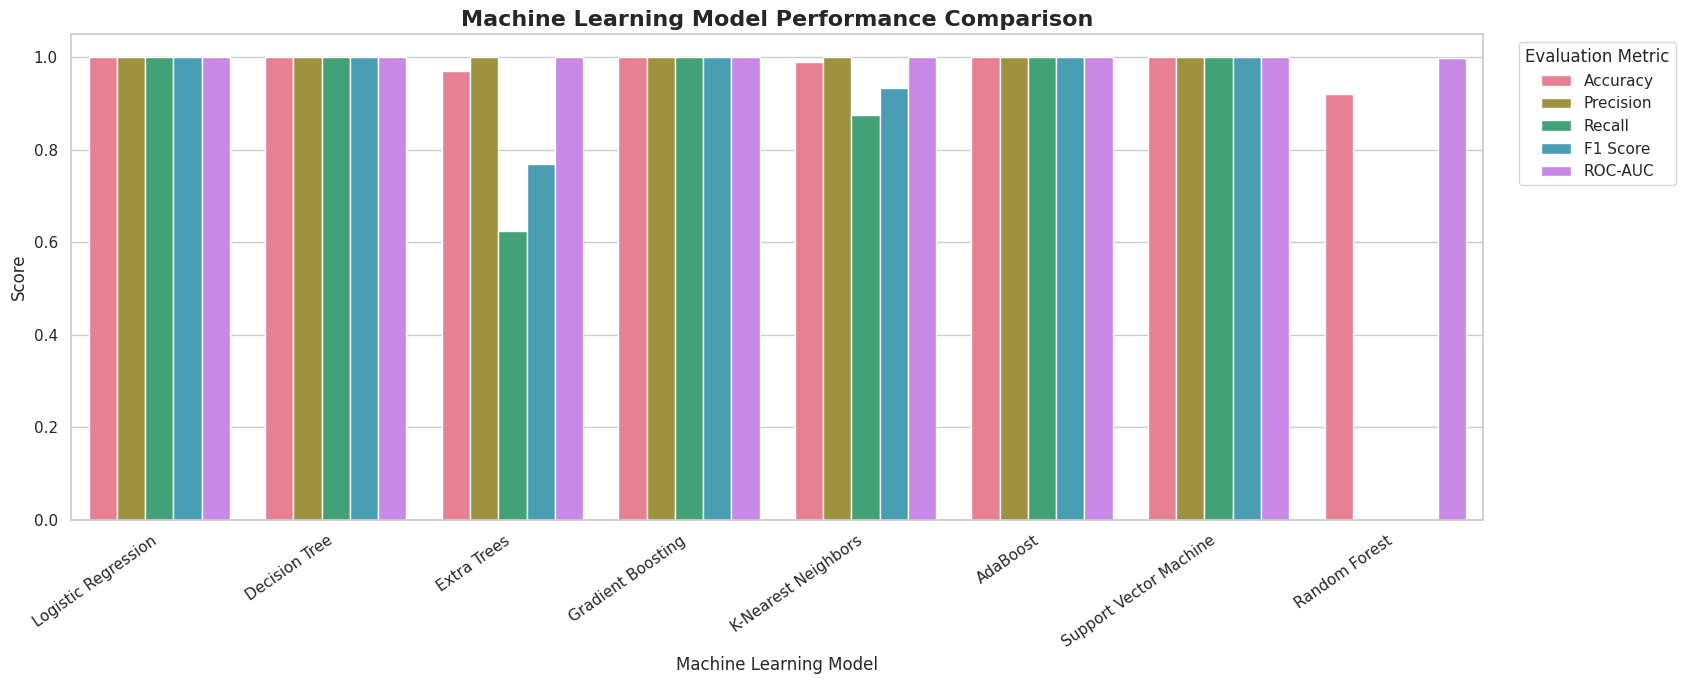

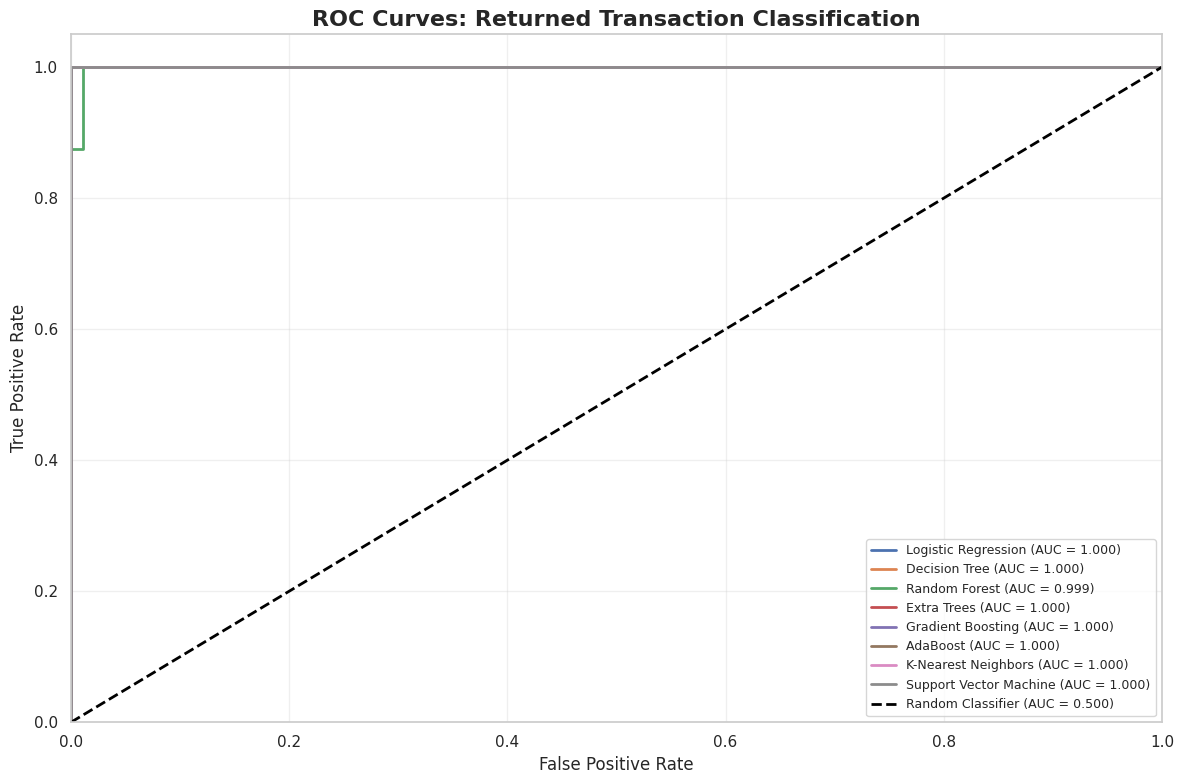


Best model based on test ROC-AUC: Logistic Regression


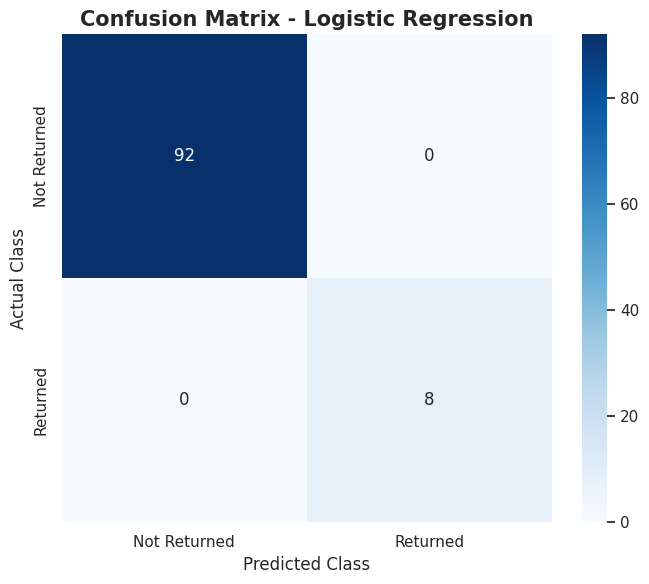


CLASSIFICATION REPORT: Logistic Regression
              precision    recall  f1-score   support

Not Returned       1.00      1.00      1.00        92
    Returned       1.00      1.00      1.00         8

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



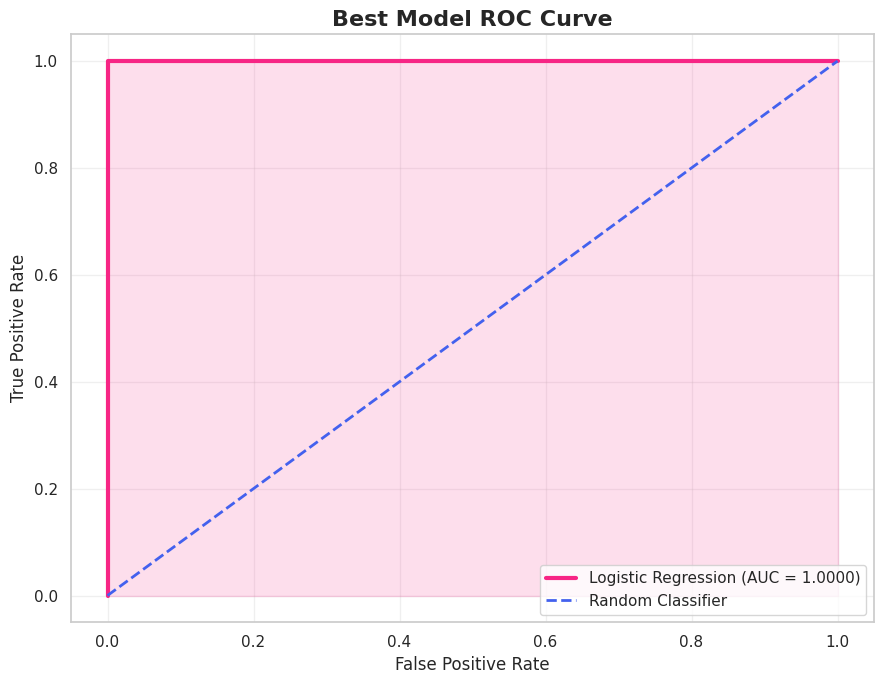

Best model ROC-AUC: 1.0000


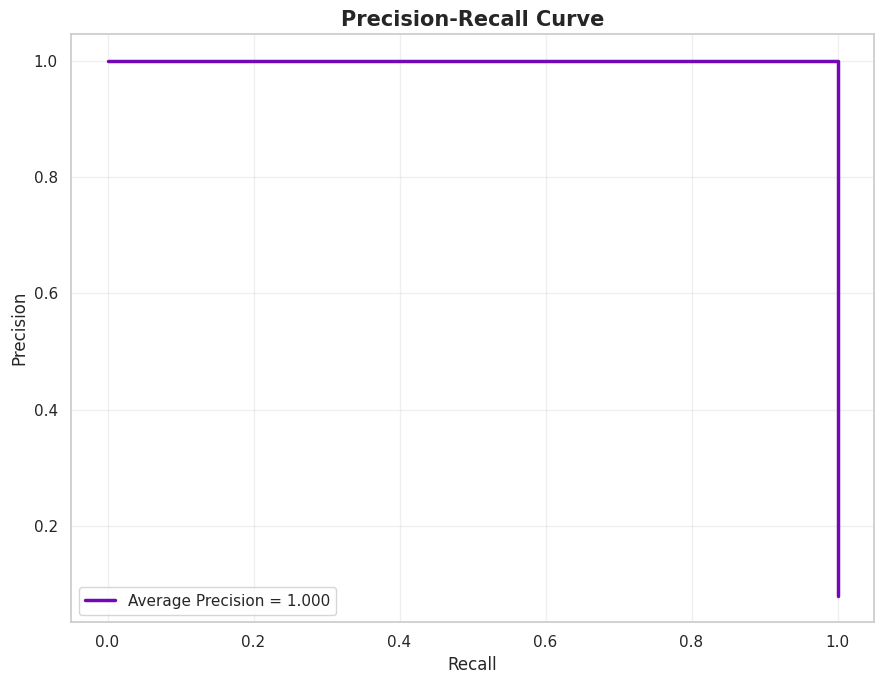


Sample predictions:


,Actual_Return_Status,Predicted_Return_Status,Probability_of_Returned
61,Not Returned,Not Returned,0.0039
329,Not Returned,Not Returned,0.0043
37,Not Returned,Not Returned,0.0065
352,Not Returned,Not Returned,0.0033
13,Not Returned,Not Returned,0.0036
57,Not Returned,Not Returned,0.0032
83,Not Returned,Not Returned,0.0040
399,Not Returned,Not Returned,0.0052
200,Not Returned,Not Returned,0.0026
481,Returned,Returned,0.9962


Logistic Regression does not expose built-in feature importance. Use permutation importance if required.

Saved files:
1. retail_model_comparison.csv
2. retail_test_predictions.csv

MACHINE LEARNING PIPELINE COMPLETED


In [14]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42
TEST_SIZE = 0.20

sns.set_theme(style="whitegrid")

# ------------------------------------------------
# 1. DATA PREPARATION
# ------------------------------------------------

data = df.copy()
data = data.loc[:, ~data.columns.duplicated()]

print("=" * 75)
print("DATASET OVERVIEW")
print("=" * 75)
print("Dataset shape:", data.shape)
print("\nColumns:")
print(data.columns.tolist())

TARGET = "Returned"

if TARGET not in data.columns:
    raise ValueError(f"Target column '{TARGET}' is not present in df.")

# Remove records without a known target
data = data.dropna(subset=[TARGET]).copy()

# Normalize target values
target_text = (
    data[TARGET].astype(str).str.strip().str.lower()
)

target_map = {
    "yes": "Returned",
    "y": "Returned",
    "true": "Returned",
    "1": "Returned",
    "returned": "Returned",
    "no": "Not Returned",
    "n": "Not Returned",
    "false": "Not Returned",
    "0": "Not Returned",
    "not returned": "Not Returned",
    "not_returned": "Not Returned"
}

data[TARGET] = target_text.map(target_map)

# Exclude unexpected target values instead of guessing their meaning
data = data.dropna(subset=[TARGET]).copy()

print("\nTarget distribution:")
print(data[TARGET].value_counts())

if data[TARGET].nunique() != 2:
    raise ValueError(
        "The Returned target must contain both returned and not-returned "
        "classes. Check the original target values."
    )

exclude_columns = [
    TARGET,
    "Transaction_ID",
    "Contact",
    "Date",
    "Employee_Name"
]

X = data.drop(
    columns=[c for c in exclude_columns if c in data.columns]
).copy()

y = data[TARGET].copy()

# Drop entirely empty and constant feature columns
empty_columns = X.columns[X.isna().all()].tolist()
X.drop(columns=empty_columns, inplace=True)

constant_columns = [
    c for c in X.columns
    if X[c].nunique(dropna=True) <= 1
]
X.drop(columns=constant_columns, inplace=True)



# Drop rows with invalid target only; feature missing values are imputed.
print("\nFeature columns:", X.columns.tolist())
print("Number of features:", X.shape[1])

# ------------------------------------------------
# 3. TRAIN-TEST SPLIT
# ------------------------------------------------

# Stratify maintains the returned/not-returned proportion in each split.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

# ------------------------------------------------
# 4. LABEL ENCODING FOR TARGET
# ------------------------------------------------

# Encode the binary target as 0 and 1.
# Fit on training target only.
target_encoder = LabelEncoder()

y_train_encoded = pd.Series(
    target_encoder.fit_transform(y_train),
    index=y_train.index,
    name=TARGET
)

y_test_encoded = pd.Series(
    target_encoder.transform(y_test),
    index=y_test.index,
    name=TARGET
)

print("\nTarget encoding:")
for index, class_name in enumerate(target_encoder.classes_):
    print(f"{class_name} = {index}")

# ROC curves use the probability of the class encoded as 1.
positive_class = target_encoder.classes_[1]
print("\nPositive class for ROC-AUC:", positive_class)

# ------------------------------------------------
# 5. DETECT NUMERIC AND CATEGORICAL FEATURES
# ------------------------------------------------

numeric_features = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

print("\nNumeric features:", numeric_features)
print("\nCategorical features:", categorical_features)

# ------------------------------------------------
# 6. PREPROCESSING
# ------------------------------------------------

# Numeric features:
# - Fill missing values using the training median.
# - Standardize for models sensitive to feature scales.

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical features:
# - Fill missing values using the most frequent training value.
# - One-hot encode categories.
# - Unknown test categories are safely ignored.

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []

if numeric_features:
    transformers.append(
        ("numeric", numeric_transformer, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("categorical", categorical_transformer, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)


models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=RANDOM_STATE
    ),

    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=20,
        random_state=RANDOM_STATE
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.5,
        random_state=RANDOM_STATE
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=7,
        weights="distance",
        n_jobs=-1
    ),

    "Gaussian Naive Bayes": GaussianNB(),

    "Support Vector Machine": SVC(
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
}

# ------------------------------------------------
# 8. TRAIN MODELS AND EVALUATE
# ------------------------------------------------

results = []
trained_models = {}
predictions = {}
probabilities = {}

for name, classifier in models.items():

    print("\n" + "=" * 75)
    print("Training:", name)
    print("=" * 75)

    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    try:
        model_pipeline.fit(X_train, y_train_encoded)

        y_pred = model_pipeline.predict(X_test)
        y_prob = model_pipeline.predict_proba(X_test)[:, 1]

        accuracy = accuracy_score(y_test_encoded, y_pred)
        precision = precision_score(
            y_test_encoded, y_pred, zero_division=0
        )
        recall = recall_score(
            y_test_encoded, y_pred, zero_division=0
        )
        f1 = f1_score(
            y_test_encoded, y_pred, zero_division=0
        )
        auc = roc_auc_score(y_test_encoded, y_prob)

        results.append({
            "Model": name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1,
            "ROC-AUC": auc
        })

        trained_models[name] = model_pipeline
        predictions[name] = y_pred
        probabilities[name] = y_prob

        print(f"Accuracy : {accuracy:.4f}")
        print(f"Precision: {precision:.4f}")
        print(f"Recall   : {recall:.4f}")
        print(f"F1 Score : {f1:.4f}")
        print(f"ROC-AUC  : {auc:.4f}")

    except Exception as error:
        print(f"Could not train {name}: {error}")

if not results:
    raise RuntimeError(
        "No model trained successfully. Check feature data and target values."
    )

# ------------------------------------------------
# 9. MODEL COMPARISON TABLE
# ------------------------------------------------

results_df = pd.DataFrame(results).sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 75)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 75)

display(results_df.round(4))

# ------------------------------------------------
# 10. MODEL COMPARISON BAR CHART
# ------------------------------------------------

metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

results_long = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(17, 7))
sns.barplot(
    data=results_long,
    x="Model",
    y="Score",
    hue="Metric",
    palette="husl"
)
plt.title(
    "Machine Learning Model Performance Comparison",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=35, ha="right")
plt.legend(title="Evaluation Metric", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 11. ROC CURVE FOR ALL MODELS
# ------------------------------------------------

plt.figure(figsize=(12, 8))

for name, y_prob in probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_test_encoded,
        y_prob,
        pos_label=1
    )

    auc_value = roc_auc_score(y_test_encoded, y_prob)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

# Random-classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    linewidth=2,
    label="Random Classifier (AUC = 0.500)"
)

plt.title(
    "ROC Curves: Returned Transaction Classification",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 12. CONFUSION MATRIX FOR BEST ROC-AUC MODEL
# ------------------------------------------------

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_predictions = predictions[best_model_name]
best_probabilities = probabilities[best_model_name]

print("\nBest model based on test ROC-AUC:", best_model_name)

cm = confusion_matrix(
    y_test_encoded,
    best_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_
)
plt.title(
    f"Confusion Matrix - {best_model_name}",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 13. CLASSIFICATION REPORT
# ------------------------------------------------

print("\n" + "=" * 75)
print(f"CLASSIFICATION REPORT: {best_model_name}")
print("=" * 75)

print(
    classification_report(
        y_test_encoded,
        best_predictions,
        labels=[0, 1],
        target_names=target_encoder.classes_,
        zero_division=0
    )
)

# ------------------------------------------------
# 14. BEST MODEL ROC CURVE
# ------------------------------------------------

fpr, tpr, thresholds = roc_curve(
    y_test_encoded,
    best_probabilities,
    pos_label=1
)

best_auc = roc_auc_score(y_test_encoded, best_probabilities)

plt.figure(figsize=(9, 7))
plt.plot(
    fpr,
    tpr,
    color="#F72585",
    linewidth=3,
    label=f"{best_model_name} (AUC = {best_auc:.4f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="#4361EE",
    linewidth=2,
    label="Random Classifier"
)
plt.fill_between(
    fpr,
    tpr,
    alpha=0.15,
    color="#F72585"
)
plt.title("Best Model ROC Curve", fontsize=16, fontweight="bold")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Best model ROC-AUC: {best_auc:.4f}")

# ------------------------------------------------
# 15. PRECISION-RECALL / THRESHOLD ANALYSIS
# ------------------------------------------------

from sklearn.metrics import precision_recall_curve, average_precision_score

precision_values, recall_values, pr_thresholds = (
    precision_recall_curve(y_test_encoded, best_probabilities)
)

average_precision = average_precision_score(
    y_test_encoded, best_probabilities
)

plt.figure(figsize=(9, 7))
plt.plot(
    recall_values,
    precision_values,
    color="#7209B7",
    linewidth=2.5,
    label=f"Average Precision = {average_precision:.3f}"
)
plt.title("Precision-Recall Curve", fontsize=15, fontweight="bold")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 16. PREDICT RETURN PROBABILITIES
# ------------------------------------------------

prediction_output = pd.DataFrame({
    "Actual_Return_Status": target_encoder.inverse_transform(
        y_test_encoded.to_numpy()
    ),
    "Predicted_Return_Status": target_encoder.inverse_transform(
        best_predictions
    ),
    "Probability_of_Returned": best_probabilities
}, index=y_test.index)

print("\nSample predictions:")
display(prediction_output.head(20).round(4))

# ------------------------------------------------
# 17. FEATURE IMPORTANCE (TREE-BASED MODELS ONLY)
# ------------------------------------------------

classifier = best_model.named_steps["classifier"]
fitted_preprocessor = best_model.named_steps["preprocessor"]

if hasattr(classifier, "feature_importances_"):

    feature_names = fitted_preprocessor.get_feature_names_out()
    importance_values = classifier.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance_values
    }).sort_values(
        "Importance",
        ascending=False
    ).head(20)

    print("\nTop 20 Important Features:")
    display(importance_df.round(5))

    plt.figure(figsize=(12, 8))
    sns.barplot(
        data=importance_df,
        x="Importance",
        y="Feature",
        hue="Feature",
        palette="viridis",
        legend=False
    )
    plt.title(
        f"Top Feature Importances - {best_model_name}",
        fontsize=15,
        fontweight="bold"
    )
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

else:
    print(
        f"{best_model_name} does not expose built-in feature importance. "
        "Use permutation importance if required."
    )

# ------------------------------------------------
# 18. SAVE MODEL COMPARISON AND TEST PREDICTIONS
# ------------------------------------------------

results_df.to_csv("retail_model_comparison.csv", index=False)
prediction_output.to_csv("retail_test_predictions.csv", index=True)

print("\nSaved files:")
print("1. retail_model_comparison.csv")
print("2. retail_test_predictions.csv")

print("\n" + "=" * 75)
print("MACHINE LEARNING PIPELINE COMPLETED")
print("=" * 75)


## Thank you...pls upvote!!!!!!!